Device: mps

LOADING IRIS DATASET

Dataset: iris
X shape: (150, 4)
y shape: (150,)
Number of features: 4
Classes: [0 1 2]
Class distribution:
(array([0, 1, 2]), array([50, 50, 50]))

REGULARIZER: none

>>> INICIANDO reg=none | seed=1 <<<
reg=none                 | seed=01 | epoch=100 | loss=0.0483 | ce=0.0483 | val_acc=1.0000 | mean_lambda=+0.0000 | var_lambda=0.000000
reg=none                 | seed=01 | epoch=200 | loss=0.0360 | ce=0.0360 | val_acc=1.0000 | mean_lambda=+0.0000 | var_lambda=0.000000
reg=none                 | seed=01 | epoch=300 | loss=0.0340 | ce=0.0340 | val_acc=1.0000 | mean_lambda=+0.0000 | var_lambda=0.000000

Calculando Jacobiano analítico em CPU/float64 | reg=none | seed=1

Spectral variance decomposition | reg=none | seed=1 | global=3.172369 | within=1.322042 | between=1.850328 | error=4.441e-16

Eigensolver até agora | eigvalsh=380 | eigvals fallback=0 | fallback rate=0.00000000%

>>> INICIANDO reg=none | seed=2 <<<
reg=none                 | seed=02 | epoch=

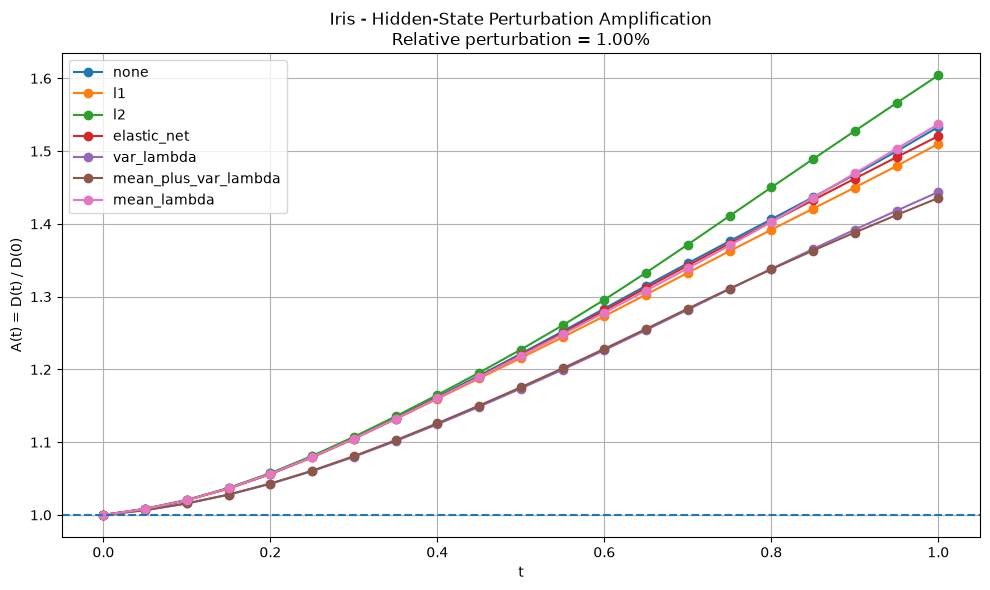

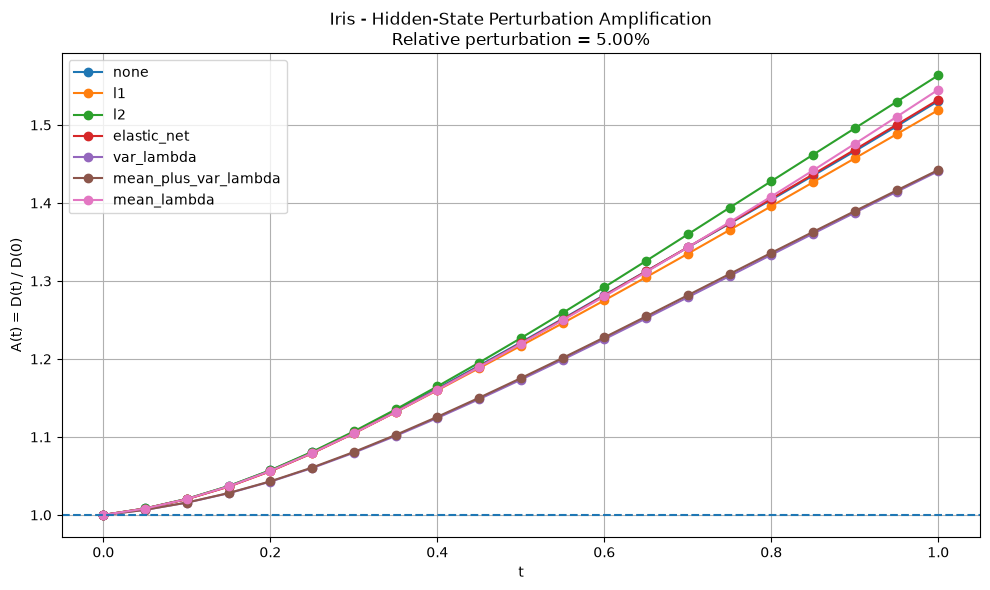

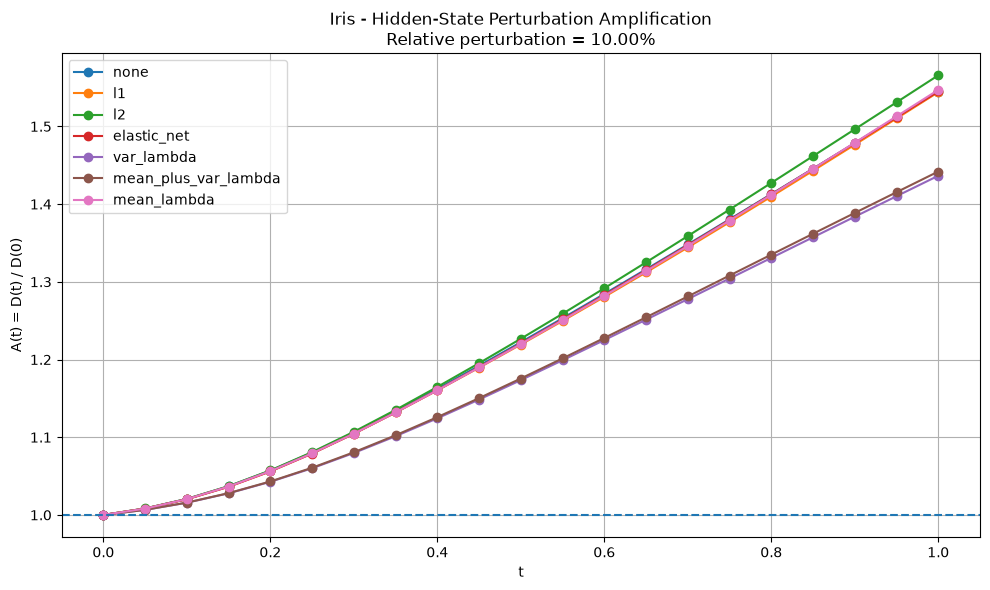

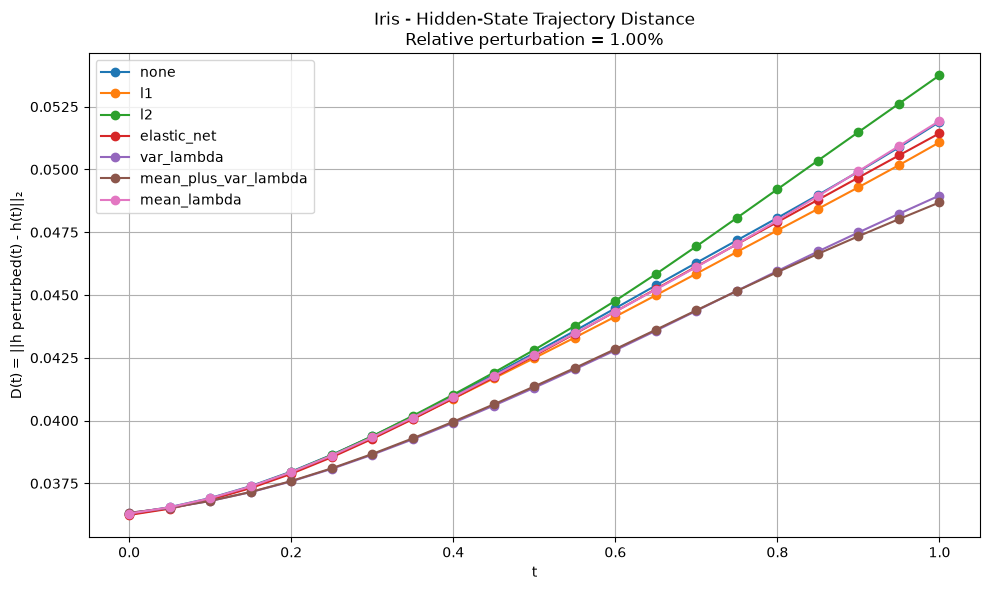

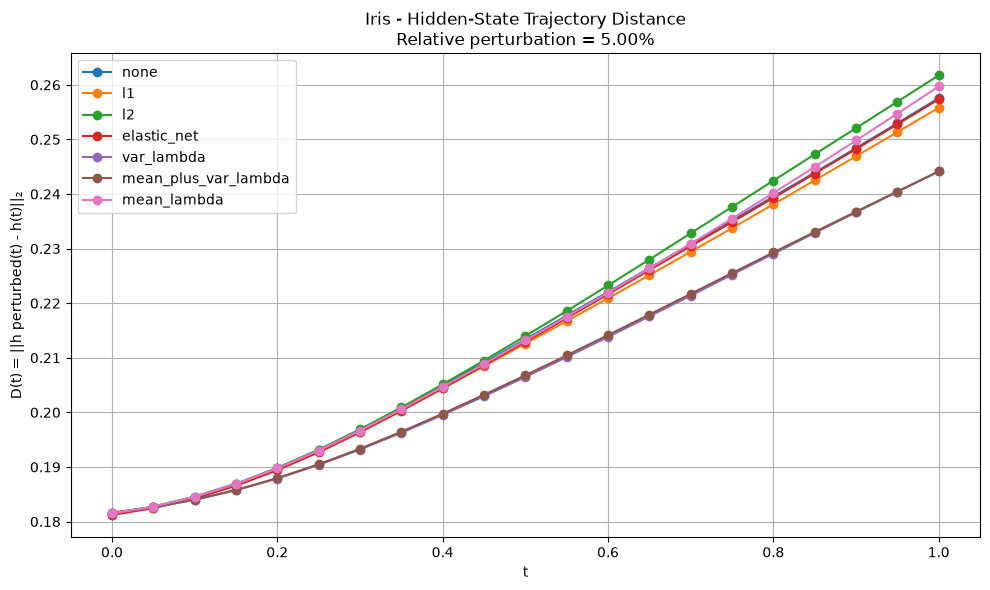

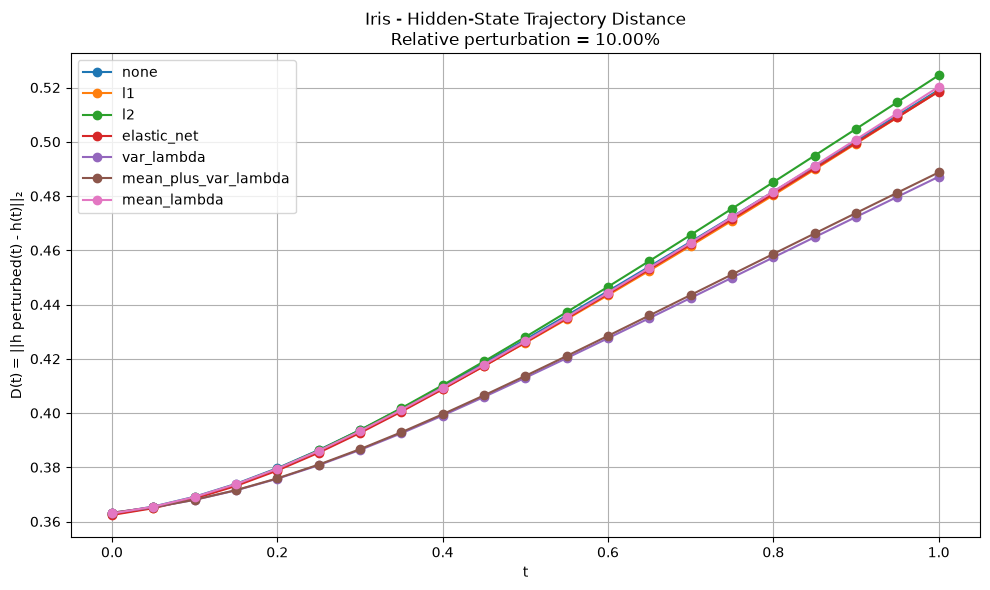

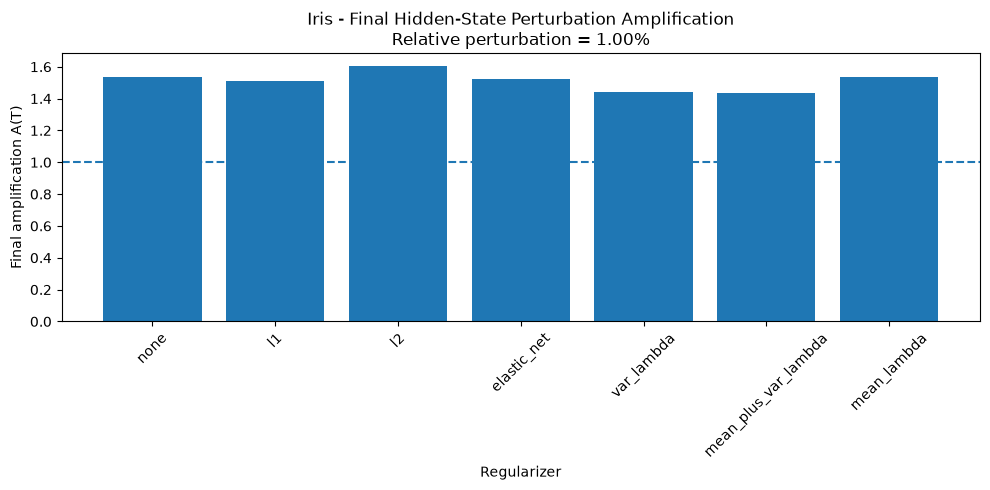

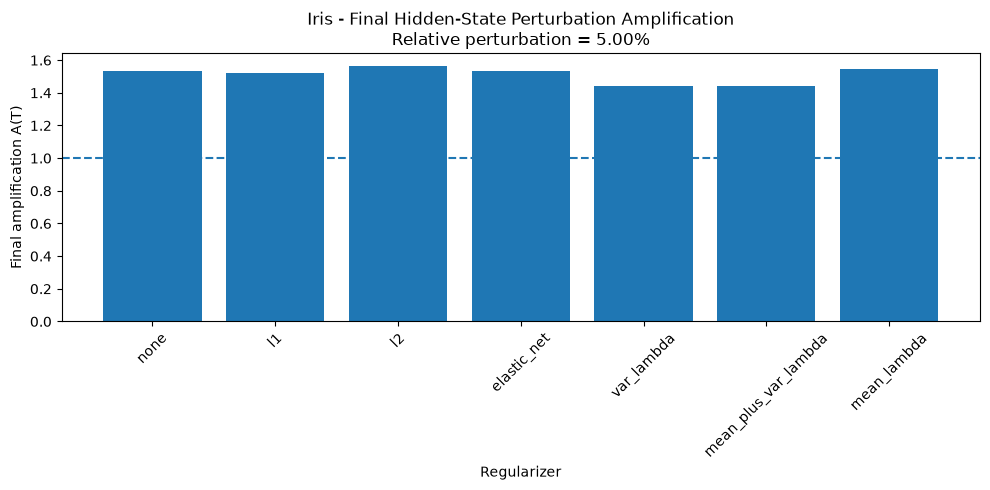

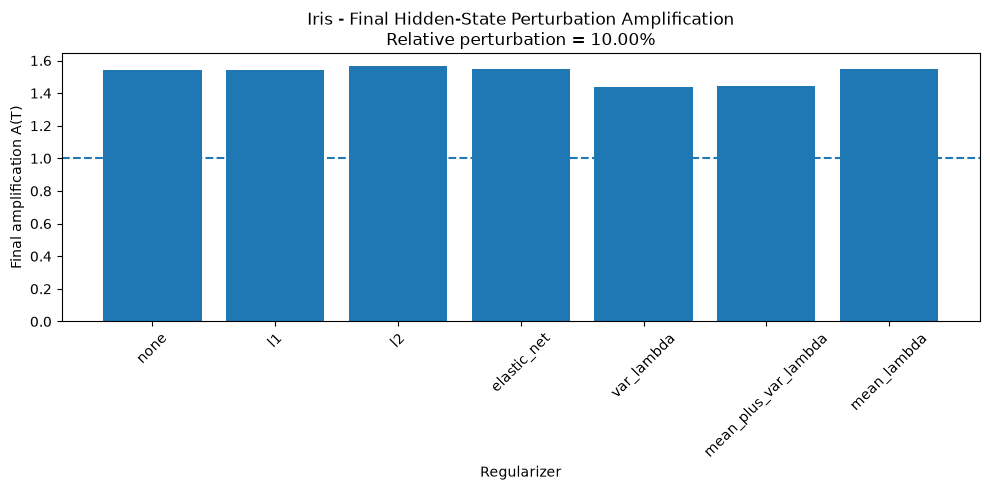

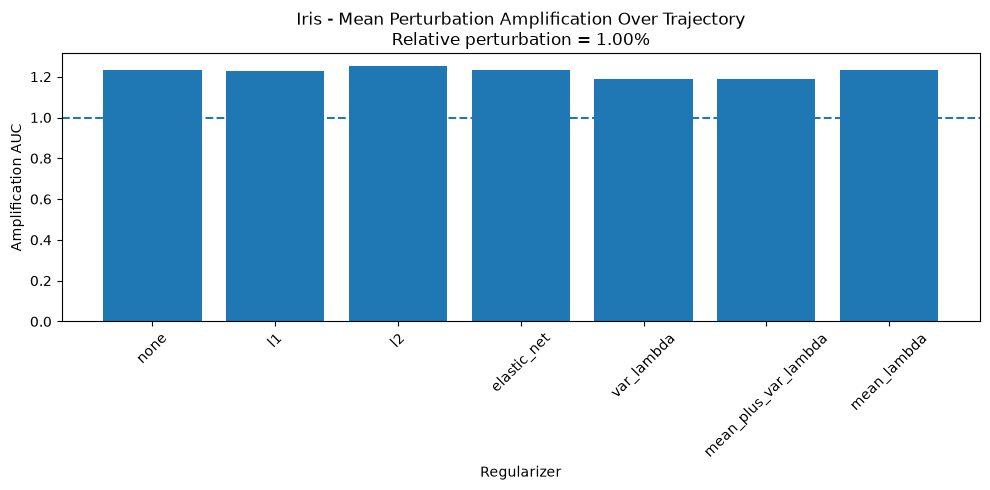

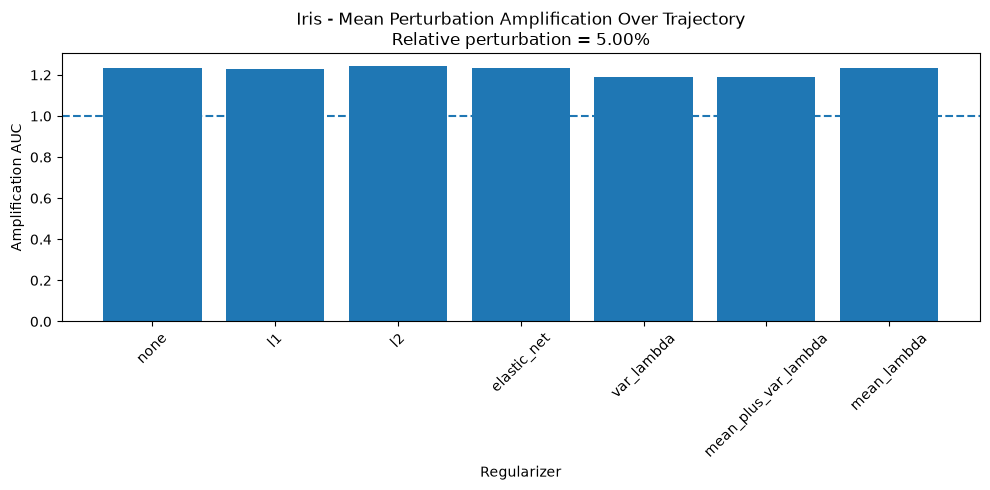

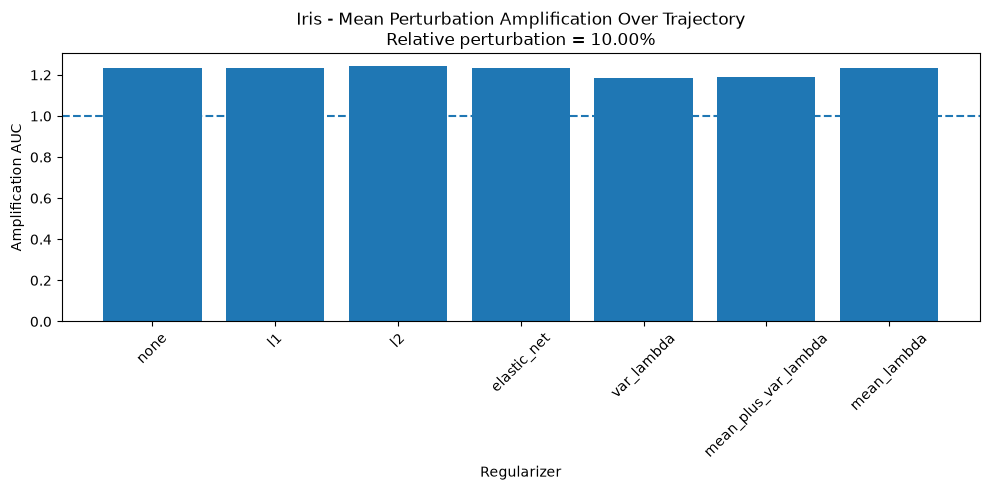


EIGENSOLVER STATISTICS
eigvalsh successful calculations: 943800
eigvals fallbacks: 0
Fallback rate: 0.00000000%

EXPERIMENT FINISHED

Dataset: IRIS - 150 samples
RK4 step_size: 0.05
Train/validation split: stratified, random_state = seed
Spectral training subset: 8 samples dynamically selected per seed/epoch
Spectral subset pairing: identical between spectral regularizers for the same seed/epoch
Post-training var_lambda: global variance over samples x times
Additional metrics: var_lambda_within_time and var_lambda_between_time
Variance decomposition: automatically checked for every regularizer/seed

Output prefix: 260920_iris_v2


In [1]:
# ============================================================
# NEURAL ODE - IRIS
# Apple Silicon / MPS
#
# ============================================================
# PROTOCOLO V2 + VARIÂNCIA ESPECTRAL GLOBAL
# ============================================================
#
# ALTERAÇÕES IMPLEMENTADAS:
#
# 1) CRÍTICA:
#    RK4 com step_size explícito e idêntico em TODAS
#    as chamadas de odeint:
#
#        step_size = 0.05
#
# 2) ALTA:
#    Split treino/validação diferente para cada seed:
#
#        random_state = seed
#
#    O mesmo split é reutilizado por todos os regularizadores
#    daquela seed.
#
# 3) ALTA:
#    Regularização espectral com 8 exemplos sorteados
#    novamente a cada época.
#
#    A seleção é determinística por:
#
#        (seed, epoch)
#
#    Portanto:
#
#        var_lambda
#        mean_lambda
#        mean_plus_var_lambda
#
#    recebem exatamente os MESMOS exemplos na mesma
#    seed/época.
#
# 4) VARIÂNCIA ESPECTRAL GLOBAL:
#
#    A métrica principal pós-treinamento passa a ser:
#
#        var_lambda =
#        Var_{samples,times}(lambda_max)
#
#    alinhada com a definição usada durante treinamento.
#
#    Também são armazenadas:
#
#        var_lambda_within_time
#        var_lambda_between_time
#
#    e validada automaticamente:
#
#        Var_global
#        =
#        Var_within_time
#        +
#        Var_between_time
#
# ============================================================
# MANTIDO:
#
# seeds = 1..30
# epochs = 300
# hidden_dim = 32
# lr = 1e-3
#
# alpha_mean = 1e-4
# beta_var = 1e-3
#
# max_reg_samples = 8
#
# L1 / L2 / Elastic Net = 1e-5
#
# Perturbações = 1%, 5%, 10%
# 10 direções por modelo
#
# Jacobiano analítico:
#
#        J = W3 D2 W2 D1 W1
#
# Avaliação espectral:
#        até 64 observações
#        10 tempos
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import random
import gc

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt

from torchdiffeq import odeint

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. DEVICE
# ============================================================

if torch.backends.mps.is_available():

    device = torch.device("mps")

elif torch.cuda.is_available():

    device = torch.device("cuda")

else:

    device = torch.device("cpu")


print("Device:", device)


# ============================================================
# 2. REPRODUTIBILIDADE
# ============================================================

def set_seed(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(seed)


# ============================================================
# 3. CONFIGURAÇÃO EXPERIMENTAL
# ============================================================

dataset_type = "iris"


seeds = list(
    range(1, 31)
)


reg_types = [

    "none",

    "l1",

    "l2",

    "elastic_net",

    "var_lambda",

    "mean_plus_var_lambda",

    "mean_lambda",

]


epochs = 300

lr = 1e-3

hidden_dim = 32


# ============================================================
# ALTERAÇÃO CRÍTICA
#
# Mesmo step_size RK4 para:
#
# - forward
# - regularização espectral
# - avaliação Jacobiana
# - estabilidade / perturbação
# ============================================================

RK4_STEP_SIZE = 0.05


RK4_OPTIONS = {

    "step_size": RK4_STEP_SIZE

}


# ============================================================
# 4. REGULARIZAÇÃO ESPECTRAL
# ============================================================

alpha_mean = 1e-4

beta_var = 1e-3

max_reg_samples = 8


# ============================================================
# 5. REGULARIZAÇÕES CLÁSSICAS
# ============================================================

lambda_l1 = 1e-5

lambda_l2 = 1e-5

lambda_elastic_l1 = 1e-5

lambda_elastic_l2 = 1e-5


# ============================================================
# 6. PERTURBAÇÕES NO ESTADO OCULTO
# ============================================================

hidden_perturbation_levels = [

    0.01,

    0.05,

    0.10,

]


n_perturbation_repeats = 10

stability_time_points = 21


# ============================================================
# 7. ESTATÍSTICAS DO EIGENSOLVER
# ============================================================

eigen_solver_stats = {

    "eigvalsh_success": 0,

    "eigvals_fallback": 0,

}


# ============================================================
# 8. AMOSTRA ESPECTRAL DETERMINÍSTICA POR SEED/EPOCH
# ============================================================

def get_spectral_sample_indices(

    n_total,

    n_samples,

    seed,

    epoch

):

    n_samples = min(
        n_total,
        n_samples
    )


    sampling_seed = (

        1_000_000

        +

        seed * 10_000

        +

        epoch

    )


    rng = np.random.default_rng(

        sampling_seed

    )


    indices = rng.choice(

        n_total,

        size=n_samples,

        replace=False

    )


    return indices


# ============================================================
# 9. ODE FUNCTION
# ============================================================

class ODEFunc(nn.Module):

    def __init__(
        self,
        hidden_dim
    ):

        super().__init__()


        self.net = nn.Sequential(

            nn.Linear(
                hidden_dim,
                64
            ),

            nn.Tanh(),

            nn.Linear(
                64,
                64
            ),

            nn.Tanh(),

            nn.Linear(
                64,
                hidden_dim
            )

        )


    def forward(
        self,
        t,
        h
    ):

        return self.net(
            h
        )


# ============================================================
# 10. NEURAL ODE CLASSIFIER
# ============================================================

class NeuralODEClassifier(nn.Module):

    def __init__(

        self,

        input_dim,

        hidden_dim=32,

        num_classes=3

    ):

        super().__init__()


        self.encoder = nn.Linear(

            input_dim,

            hidden_dim

        )


        self.odefunc = ODEFunc(

            hidden_dim

        )


        self.decoder = nn.Linear(

            hidden_dim,

            num_classes

        )


    def forward(

        self,

        x,

        return_traj=False

    ):

        h0 = self.encoder(
            x
        )


        t = torch.tensor(

            [
                0.0,
                1.0
            ],

            dtype=x.dtype,

            device=x.device

        )


        h_t = odeint(

            self.odefunc,

            h0,

            t,

            method="rk4",

            options=RK4_OPTIONS

        )


        h_final = h_t[-1]


        logits = self.decoder(

            h_final

        )


        if return_traj:

            return (
                logits,
                h_t
            )


        return logits


# ============================================================
# 11. JACOBIANO ANALÍTICO EXATO
#
# J(h) = W3 D2 W2 D1 W1
# ============================================================

def analytical_jacobian(

    odefunc,

    h

):

    if h.dim() == 2:

        if h.shape[0] != 1:

            raise ValueError(

                "analytical_jacobian expects "
                "exactly one hidden state."

            )

        h = h.squeeze(0)


    if h.dim() != 1:

        raise ValueError(

            "analytical_jacobian expects "
            "a one-dimensional hidden state."

        )


    layer1 = odefunc.net[0]

    layer2 = odefunc.net[2]

    layer3 = odefunc.net[4]


    W1 = layer1.weight
    b1 = layer1.bias

    W2 = layer2.weight
    b2 = layer2.bias

    W3 = layer3.weight


    z1 = W1 @ h + b1

    a1 = torch.tanh(z1)


    z2 = W2 @ a1 + b2

    a2 = torch.tanh(z2)


    d1 = 1.0 - a1.pow(2)

    d2 = 1.0 - a2.pow(2)


    D1_W1 = (

        d1.unsqueeze(1)

        *

        W1

    )


    W2_D1_W1 = (

        W2

        @

        D1_W1

    )


    D2_W2_D1_W1 = (

        d2.unsqueeze(1)

        *

        W2_D1_W1

    )


    J = (

        W3

        @

        D2_W2_D1_W1

    )


    return J


# ============================================================
# 12. ROBUST LAMBDA_MAX
# ============================================================

def robust_lambda_max_from_jacobian(

    J

):

    global eigen_solver_stats


    if not torch.isfinite(J).all():

        raise RuntimeError(

            "Jacobian contains NaN or Inf "
            "before CPU transfer."

        )


    if J.device.type == "mps":

        torch.mps.synchronize()


    J_cpu_f32 = J.to(

        device="cpu"

    )


    if J.device.type == "mps":

        torch.mps.synchronize()


    if not torch.isfinite(
        J_cpu_f32
    ).all():

        raise RuntimeError(

            "Jacobian became non-finite during "
            "MPS float32 -> CPU float32 transfer."

        )


    J_cpu = J_cpu_f32.to(

        dtype=torch.float64

    )


    if not torch.isfinite(
        J_cpu
    ).all():

        raise RuntimeError(

            "Jacobian became non-finite during "
            "CPU float32 -> CPU float64 conversion."

        )


    S_cpu = (

        0.5 * J_cpu

        +

        0.5 * J_cpu.T

    )


    # Re-simetrização numérica

    S_cpu = (

        0.5 * S_cpu

        +

        0.5 * S_cpu.T

    )


    if not torch.isfinite(
        S_cpu
    ).all():

        raise RuntimeError(

            "Matrix S contains NaN or Inf."

        )


    try:

        eigvals = torch.linalg.eigvalsh(

            S_cpu

        )


        if not torch.isfinite(
            eigvals
        ).all():

            raise RuntimeError(

                "eigvalsh returned "
                "non-finite eigenvalues."

            )


        eigen_solver_stats[
            "eigvalsh_success"
        ] += 1


        lambda_max_cpu_f64 = (

            eigvals[-1]

        )


    except RuntimeError as primary_error:

        eigen_solver_stats[
            "eigvals_fallback"
        ] += 1


        print(
            "\nWarning: eigvalsh failed."
        )


        print(
            "Using eigvals fallback."
        )


        print(
            "Original error:",
            str(primary_error)
        )


        eigvals_general = torch.linalg.eigvals(

            S_cpu

        )


        eigvals_real = eigvals_general.real


        if not torch.isfinite(
            eigvals_real
        ).all():

            raise RuntimeError(

                "eigvals fallback returned "
                "non-finite eigenvalues."

            )


        lambda_max_cpu_f64 = (

            eigvals_real.max()

        )


    lambda_max_cpu_original_dtype = (

        lambda_max_cpu_f64.to(

            dtype=J.dtype

        )

    )


    lambda_max = (

        lambda_max_cpu_original_dtype.to(

            device=J.device

        )

    )


    return lambda_max


# ============================================================
# 13. LAMBDA_MAX DA PARTE SIMÉTRICA
# ============================================================

def lambda_max_symmetric(

    odefunc,

    h

):

    # Estado tratado como ponto espectral fixo.
    # O gradiente ainda passa pelo Jacobiano em relação
    # aos parâmetros da ODEFunc.

    h = (

        h

        .detach()

        .clone()

    )


    J = analytical_jacobian(

        odefunc,

        h

    )


    if not torch.isfinite(
        J
    ).all():

        raise RuntimeError(

            "Analytical Jacobian contains "
            "NaN or Inf during training."

        )


    lambda_max = (

        robust_lambda_max_from_jacobian(

            J

        )

    )


    return lambda_max


# ============================================================
# 14. REGULARIZADOR ESPECTRAL
#
# 8 exemplos diferentes por época, deterministicamente
# pareados por seed/epoch.
# ============================================================

def spectral_regularizer(

    model,

    x_batch,

    seed,

    epoch

):

    n = min(

        x_batch.shape[0],

        max_reg_samples

    )


    sample_indices_np = (

        get_spectral_sample_indices(

            n_total=
                x_batch.shape[0],

            n_samples=
                n,

            seed=
                seed,

            epoch=
                epoch

        )

    )


    sample_indices = torch.tensor(

        sample_indices_np,

        dtype=torch.long,

        device=x_batch.device

    )


    x_reg = x_batch.index_select(

        0,

        sample_indices

    )


    h0 = model.encoder(

        x_reg

    )


    # Tempos usados para AMOSTRAR lambda.
    # A integração interna permanece com step_size=0.05.

    t_eval = torch.linspace(

        0.0,

        1.0,

        4,

        dtype=x_batch.dtype,

        device=x_batch.device

    )


    h_traj = odeint(

        model.odefunc,

        h0,

        t_eval,

        method="rk4",

        options=RK4_OPTIONS

    )


    lambdas = []


    for k in range(
        len(t_eval)
    ):

        for i in range(n):

            h = h_traj[
                k,
                i
            ]


            lam = lambda_max_symmetric(

                model.odefunc,

                h

            )


            lambdas.append(
                lam
            )


    lambdas = torch.stack(

        lambdas

    )


    # ========================================================
    # IMPORTANTE:
    #
    # lambdas contém todos os:
    #
    # samples x times
    #
    # Logo esta é uma variância GLOBAL.
    # ========================================================

    mean_lambda = (

        lambdas.mean()

    )


    var_lambda = (

        lambdas.var(

            unbiased=False

        )

    )


    return (

        mean_lambda,

        var_lambda,

        lambdas

    )


# ============================================================
# 15. MÉTRICAS JACOBIANAS PÓS-TREINAMENTO
#
# Agora retorna também todos os lambda individuais.
# ============================================================

def jacobian_metrics_cpu(

    odefunc_cpu,

    h_batch_cpu,

    max_points=64

):

    odefunc_cpu.eval()


    h_batch_cpu = h_batch_cpu[
        :max_points
    ]


    frob_list = []

    frob_sq_list = []

    lambda_list = []


    for i in range(

        h_batch_cpu.shape[0]

    ):


        h = (

            h_batch_cpu[
                i:i+1
            ]

            .detach()

            .clone()

            .to(

                device="cpu",

                dtype=torch.float64

            )

        )


        if not torch.isfinite(
            h
        ).all():

            raise RuntimeError(

                f"Hidden state contains NaN/Inf. "
                f"sample={i}"

            )


        J = analytical_jacobian(

            odefunc_cpu,

            h

        )


        if not torch.isfinite(
            J
        ).all():

            raise RuntimeError(

                f"Analytical Jacobian contains "
                f"NaN/Inf in CPU/float64. "
                f"sample={i}"

            )


        frob = torch.norm(

            J,

            p="fro"

        )


        frob_sq = (

            frob ** 2

        )


        lambda_max = (

            robust_lambda_max_from_jacobian(

                J

            )

        )


        frob_list.append(

            frob

        )


        frob_sq_list.append(

            frob_sq

        )


        lambda_list.append(

            lambda_max

        )


    frob_tensor = torch.stack(

        frob_list

    )


    frob_sq_tensor = torch.stack(

        frob_sq_list

    )


    lambda_tensor = torch.stack(

        lambda_list

    )


    # Valores individuais em um determinado tempo

    lambda_values = (

        lambda_tensor

        .detach()

        .cpu()

        .numpy()

        .astype(
            np.float64
        )

    )


    return {

        "frob_mean":
            frob_tensor.mean().item(),

        "frob_sq_mean":
            frob_sq_tensor.mean().item(),

        "lambda_mean":
            lambda_tensor.mean().item(),

        # Variância entre amostras condicionada ao tempo

        "lambda_var_within_time":
            lambda_tensor.var(
                unbiased=False
            ).item(),

        "lambda_max":
            lambda_tensor.max().item(),

        # Valores usados posteriormente na variância global

        "lambda_values":
            lambda_values,

    }


# ============================================================
# 16. AVALIAÇÃO JACOBIANA EM CPU / FLOAT64
# ============================================================

def evaluate_jacobian_trajectory_cpu(

    model,

    X_val,

    max_points=64,

    n_time_points=10

):

    for name, param in model.named_parameters():

        if not torch.isfinite(
            param
        ).all():

            raise RuntimeError(

                f"Model parameter contains "
                f"NaN/Inf: {name}"

            )


    model_cpu = NeuralODEClassifier(

        input_dim=
            model.encoder.in_features,

        hidden_dim=
            model.encoder.out_features,

        num_classes=
            model.decoder.out_features

    )


    state_dict_cpu = {

        key:
            value
            .detach()
            .cpu()

        for key, value
        in model.state_dict().items()

    }


    model_cpu.load_state_dict(

        state_dict_cpu

    )


    model_cpu = model_cpu.to(

        device="cpu",

        dtype=torch.float64

    )


    model_cpu.eval()


    X_cpu = (

        X_val[
            :max_points
        ]

        .detach()

        .cpu()

        .to(
            dtype=torch.float64
        )

    )


    with torch.no_grad():

        h0_cpu = model_cpu.encoder(

            X_cpu

        )


    if not torch.isfinite(
        h0_cpu
    ).all():

        raise RuntimeError(

            "h0 contains NaN/Inf "
            "in CPU/float64."

        )


    t_eval_cpu = torch.linspace(

        0.0,

        1.0,

        n_time_points,

        dtype=torch.float64,

        device="cpu"

    )


    with torch.no_grad():

        h_traj_cpu = odeint(

            model_cpu.odefunc,

            h0_cpu,

            t_eval_cpu,

            method="rk4",

            options=RK4_OPTIONS

        )


    if not torch.isfinite(
        h_traj_cpu
    ).all():

        raise RuntimeError(

            "Hidden trajectory contains "
            "NaN/Inf even in CPU/float64."

        )


    trajectory_metrics = []


    for k in range(

        len(t_eval_cpu)

    ):


        metrics = jacobian_metrics_cpu(

            model_cpu.odefunc,

            h_traj_cpu[k],

            max_points=
                max_points

        )


        trajectory_metrics.append(

            metrics

        )


    del model_cpu
    del state_dict_cpu
    del X_cpu
    del h0_cpu
    del h_traj_cpu

    gc.collect()


    return trajectory_metrics


# ============================================================
# 17. HIDDEN-STATE STABILITY EXPERIMENT
# ============================================================

@torch.no_grad()
def evaluate_hidden_state_stability(

    model,

    X,

    y,

    relative_perturbation,

    t_eval,

    perturbation_seed,

    n_repeats=10

):

    model.eval()


    h0 = model.encoder(

        X

    )


    if not torch.isfinite(
        h0
    ).all():

        raise RuntimeError(

            "Non-finite h0 detected during "
            "stability evaluation."

        )


    clean_traj = odeint(

        model.odefunc,

        h0,

        t_eval,

        method="rk4",

        options=RK4_OPTIONS

    )


    if not torch.isfinite(
        clean_traj
    ).all():

        raise RuntimeError(

            "Non-finite clean trajectory detected "
            "during stability evaluation."

        )


    clean_final = clean_traj[-1]


    clean_logits = model.decoder(

        clean_final

    )


    clean_pred = clean_logits.argmax(

        dim=1

    )


    clean_accuracy = (

        clean_pred

        ==

        y

    ).float().mean().item()


    distance_repeats = []

    amplification_repeats = []

    final_logit_changes = []

    prediction_flip_rates = []

    perturbed_accuracies = []


    for repeat in range(

        n_repeats

    ):


        rng = np.random.default_rng(

            perturbation_seed

            +

            repeat

        )


        random_direction_np = rng.normal(

            loc=0.0,

            scale=1.0,

            size=tuple(
                h0.shape
            )

        ).astype(

            np.float32

        )


        random_direction = torch.tensor(

            random_direction_np,

            dtype=h0.dtype,

            device=h0.device

        )


        direction_norm = torch.linalg.vector_norm(

            random_direction,

            ord=2,

            dim=1,

            keepdim=True

        )


        random_direction = (

            random_direction

            /

            (

                direction_norm

                +

                1e-12

            )

        )


        h0_norm = torch.linalg.vector_norm(

            h0,

            ord=2,

            dim=1,

            keepdim=True

        )


        perturbation_norm = (

            relative_perturbation

            *

            torch.clamp(

                h0_norm,

                min=1e-8

            )

        )


        delta_h0 = (

            random_direction

            *

            perturbation_norm

        )


        h0_perturbed = (

            h0

            +

            delta_h0

        )


        perturbed_traj = odeint(

            model.odefunc,

            h0_perturbed,

            t_eval,

            method="rk4",

            options=RK4_OPTIONS

        )


        if not torch.isfinite(
            perturbed_traj
        ).all():

            raise RuntimeError(

                "Non-finite perturbed trajectory "
                "detected."

            )


        distance = torch.linalg.vector_norm(

            perturbed_traj

            -

            clean_traj,

            ord=2,

            dim=2

        )


        initial_distance = torch.linalg.vector_norm(

            delta_h0,

            ord=2,

            dim=1

        )


        amplification = (

            distance

            /

            (

                initial_distance.unsqueeze(0)

                +

                1e-12

            )

        )


        distance_repeats.append(

            distance

        )


        amplification_repeats.append(

            amplification

        )


        perturbed_final = (

            perturbed_traj[-1]

        )


        perturbed_logits = model.decoder(

            perturbed_final

        )


        perturbed_pred = perturbed_logits.argmax(

            dim=1

        )


        perturbed_accuracy = (

            perturbed_pred

            ==

            y

        ).float().mean()


        prediction_flip_rate = (

            perturbed_pred

            !=

            clean_pred

        ).float().mean()


        logit_change = torch.linalg.vector_norm(

            perturbed_logits

            -

            clean_logits,

            ord=2,

            dim=1

        )


        final_logit_changes.append(

            logit_change

        )


        prediction_flip_rates.append(

            prediction_flip_rate

        )


        perturbed_accuracies.append(

            perturbed_accuracy

        )


    distances = torch.stack(

        distance_repeats,

        dim=0

    )


    amplifications = torch.stack(

        amplification_repeats,

        dim=0

    )


    final_logit_changes = torch.stack(

        final_logit_changes,

        dim=0

    )


    prediction_flip_rates = torch.stack(

        prediction_flip_rates

    )


    perturbed_accuracies = torch.stack(

        perturbed_accuracies

    )


    distance_curve_mean = distances.mean(

        dim=(
            0,
            2
        )

    )


    distance_curve_std = distances.std(

        dim=(
            0,
            2
        ),

        unbiased=False

    )


    amplification_curve_mean = amplifications.mean(

        dim=(
            0,
            2
        )

    )


    amplification_curve_std = amplifications.std(

        dim=(
            0,
            2
        ),

        unbiased=False

    )


    final_amplification = amplifications[

        :,

        -1,

        :

    ]


    final_amplification_mean = (

        final_amplification

        .mean()

        .item()

    )


    final_amplification_std = (

        final_amplification

        .std(
            unbiased=False
        )

        .item()

    )


    final_distance = distances[

        :,

        -1,

        :

    ]


    final_distance_mean = (

        final_distance

        .mean()

        .item()

    )


    max_amplification_per_sample = (

        amplifications

        .max(
            dim=1
        )

        .values

    )


    max_amplification_mean = (

        max_amplification_per_sample

        .mean()

        .item()

    )


    # ========================================================
    # AUC DA AMPLIFICAÇÃO
    # ========================================================

    dt = (

        t_eval[1:]

        -

        t_eval[:-1]

    )


    trapezoids = (

        0.5

        *

        (

            amplifications[
                :,
                :-1,
                :
            ]

            +

            amplifications[
                :,
                1:,
                :
            ]

        )

        *

        dt.view(

            1,

            -1,

            1

        )

    )


    amplification_auc = (

        trapezoids.sum(
            dim=1
        )

        /

        (

            t_eval[-1]

            -

            t_eval[0]

        )

    )


    amplification_auc_mean = (

        amplification_auc

        .mean()

        .item()

    )


    fraction_final_contracted = (

        final_amplification

        <

        1.0

    ).float().mean().item()


    log_final_amplification = torch.log(

        final_amplification

        +

        1e-12

    )


    log_final_amplification_mean = (

        log_final_amplification

        .mean()

        .item()

    )


    perturbed_accuracy_mean = (

        perturbed_accuracies

        .mean()

        .item()

    )


    prediction_flip_rate_mean = (

        prediction_flip_rates

        .mean()

        .item()

    )


    final_logit_change_mean = (

        final_logit_changes

        .mean()

        .item()

    )


    initial_distance_mean = (

        distances[
            :,
            0,
            :
        ]

        .mean()

        .item()

    )


    return {

        "clean_accuracy":
            clean_accuracy,

        "perturbed_accuracy":
            perturbed_accuracy_mean,

        "prediction_flip_rate":
            prediction_flip_rate_mean,

        "initial_distance_mean":
            initial_distance_mean,

        "final_distance_mean":
            final_distance_mean,

        "final_amplification_mean":
            final_amplification_mean,

        "final_amplification_std":
            final_amplification_std,

        "max_amplification_mean":
            max_amplification_mean,

        "amplification_auc_mean":
            amplification_auc_mean,

        "fraction_final_contracted":
            fraction_final_contracted,

        "log_final_amplification_mean":
            log_final_amplification_mean,

        "final_logit_change_mean":
            final_logit_change_mean,

        "distance_curve_mean":
            distance_curve_mean
            .cpu()
            .numpy(),

        "distance_curve_std":
            distance_curve_std
            .cpu()
            .numpy(),

        "amplification_curve_mean":
            amplification_curve_mean
            .cpu()
            .numpy(),

        "amplification_curve_std":
            amplification_curve_std
            .cpu()
            .numpy(),

    }


# ============================================================
# 18. LOAD IRIS
# ============================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "LOADING IRIS DATASET"
)


print(
    "=" * 120
)


X_raw, y_raw = load_iris(

    return_X_y=True

)


X_raw = X_raw.astype(

    np.float32

)


y_raw = y_raw.astype(

    np.int64

)


print(
    "\nDataset:",
    dataset_type
)


print(
    "X shape:",
    X_raw.shape
)


print(
    "y shape:",
    y_raw.shape
)


print(
    "Number of features:",
    X_raw.shape[1]
)


print(
    "Classes:",
    np.unique(y_raw)
)


print(
    "Class distribution:"
)


print(

    np.unique(

        y_raw,

        return_counts=True

    )

)


assert X_raw.shape[0] == 150

assert X_raw.shape[1] == 4


input_dim = X_raw.shape[1]

num_classes = len(
    np.unique(y_raw)
)


# ============================================================
# 19. PREPARAÇÃO DOS DADOS POR SEED
# ============================================================

def prepare_data_for_seed(

    seed

):

    (

        X_train_np,

        X_val_np,

        y_train_np,

        y_val_np

    ) = train_test_split(

        X_raw,

        y_raw,

        test_size=0.25,

        stratify=y_raw,

        random_state=seed

    )


    scaler = StandardScaler()


    X_train_np = scaler.fit_transform(

        X_train_np

    )


    X_val_np = scaler.transform(

        X_val_np

    )


    X_train_np = X_train_np.astype(

        np.float32

    )


    X_val_np = X_val_np.astype(

        np.float32

    )


    X_train = torch.tensor(

        X_train_np,

        dtype=torch.float32,

        device=device

    )


    y_train = torch.tensor(

        y_train_np,

        dtype=torch.long,

        device=device

    )


    X_val = torch.tensor(

        X_val_np,

        dtype=torch.float32,

        device=device

    )


    y_val = torch.tensor(

        y_val_np,

        dtype=torch.long,

        device=device

    )


    return (

        X_train,

        y_train,

        X_val,

        y_val

    )


# ============================================================
# 20. CONTAINERS
# ============================================================

model_results_all = []

stability_seed_results_all = []

stability_trajectory_results_all = []


# ============================================================
# 21. LOOP PRINCIPAL
# ============================================================

for reg_type in reg_types:


    print(
        "\n"
        +
        "=" * 120
    )


    print(
        f"REGULARIZER: {reg_type}"
    )


    print(
        "=" * 120
    )


    for seed in seeds:


        print(

            f"\n>>> INICIANDO "
            f"reg={reg_type} | "
            f"seed={seed} <<<"

        )


        set_seed(
            seed
        )


        (

            X_train,

            y_train,

            X_val,

            y_val

        ) = prepare_data_for_seed(

            seed

        )


        model = NeuralODEClassifier(

            input_dim=
                input_dim,

            hidden_dim=
                hidden_dim,

            num_classes=
                num_classes

        ).to(
            device
        )


        optimizer = torch.optim.Adam(

            model.parameters(),

            lr=lr

        )


        # ====================================================
        # TREINAMENTO
        # ====================================================

        for epoch in range(

            1,

            epochs + 1

        ):


            model.train()


            optimizer.zero_grad()


            logits = model(

                X_train

            )


            ce = F.cross_entropy(

                logits,

                y_train

            )


            mean_lam = torch.tensor(

                0.0,

                dtype=torch.float32,

                device=device

            )


            var_lam = torch.tensor(

                0.0,

                dtype=torch.float32,

                device=device

            )


            # =================================================
            # NONE
            # =================================================

            if reg_type == "none":

                loss = ce


            # =================================================
            # L1
            # =================================================

            elif reg_type == "l1":

                l1_penalty = torch.tensor(

                    0.0,

                    device=device

                )


                for p in model.parameters():

                    l1_penalty += (

                        p.abs().sum()

                    )


                loss = (

                    ce

                    +

                    lambda_l1

                    *

                    l1_penalty

                )


            # =================================================
            # L2
            # =================================================

            elif reg_type == "l2":

                l2_penalty = torch.tensor(

                    0.0,

                    device=device

                )


                for p in model.parameters():

                    l2_penalty += (

                        p ** 2

                    ).sum()


                loss = (

                    ce

                    +

                    lambda_l2

                    *

                    l2_penalty

                )


            # =================================================
            # ELASTIC NET
            # =================================================

            elif reg_type == "elastic_net":

                l1_penalty = torch.tensor(

                    0.0,

                    device=device

                )


                l2_penalty = torch.tensor(

                    0.0,

                    device=device

                )


                for p in model.parameters():

                    l1_penalty += (

                        p.abs().sum()

                    )


                    l2_penalty += (

                        p ** 2

                    ).sum()


                loss = (

                    ce

                    +

                    lambda_elastic_l1

                    *

                    l1_penalty

                    +

                    lambda_elastic_l2

                    *

                    l2_penalty

                )


            # =================================================
            # VAR LAMBDA
            # =================================================

            elif reg_type == "var_lambda":

                (

                    mean_lam,

                    var_lam,

                    _

                ) = spectral_regularizer(

                    model,

                    X_train,

                    seed=
                        seed,

                    epoch=
                        epoch

                )


                loss = (

                    ce

                    +

                    beta_var

                    *

                    var_lam

                )


            # =================================================
            # MEAN + VAR LAMBDA
            # =================================================

            elif reg_type == "mean_plus_var_lambda":

                (

                    mean_lam,

                    var_lam,

                    _

                ) = spectral_regularizer(

                    model,

                    X_train,

                    seed=
                        seed,

                    epoch=
                        epoch

                )


                mean_penalty = F.softplus(

                    mean_lam

                )


                loss = (

                    ce

                    +

                    alpha_mean

                    *

                    mean_penalty

                    +

                    beta_var

                    *

                    var_lam

                )


            # =================================================
            # MEAN LAMBDA
            # =================================================

            elif reg_type == "mean_lambda":

                (

                    mean_lam,

                    var_lam,

                    _

                ) = spectral_regularizer(

                    model,

                    X_train,

                    seed=
                        seed,

                    epoch=
                        epoch

                )


                mean_penalty = F.softplus(

                    mean_lam

                )


                loss = (

                    ce

                    +

                    alpha_mean

                    *

                    mean_penalty

                )


            else:

                raise ValueError(

                    f"Unknown regularizer: "
                    f"{reg_type}"

                )


            if not torch.isfinite(
                loss
            ).item():

                raise RuntimeError(

                    f"Non-finite loss | "
                    f"reg={reg_type} | "
                    f"seed={seed} | "
                    f"epoch={epoch}"

                )


            loss.backward()


            torch.nn.utils.clip_grad_norm_(

                model.parameters(),

                1.0

            )


            optimizer.step()


            if epoch % 100 == 0:

                model.eval()


                with torch.no_grad():

                    val_logits = model(

                        X_val

                    )


                    val_acc_epoch = (

                        val_logits.argmax(
                            dim=1
                        )

                        ==

                        y_val

                    ).float().mean()


                print(

                    f"reg={reg_type:20s} | "
                    f"seed={seed:02d} | "
                    f"epoch={epoch:03d} | "
                    f"loss={loss.item():.4f} | "
                    f"ce={ce.item():.4f} | "
                    f"val_acc={val_acc_epoch.item():.4f} | "
                    f"mean_lambda={mean_lam.item():+.4f} | "
                    f"var_lambda={var_lam.item():.6f}"

                )


        # ====================================================
        # 22. VALIDAÇÃO FINAL
        # ====================================================

        model.eval()


        with torch.no_grad():

            val_logits = model(

                X_val

            )


            val_acc = (

                val_logits.argmax(
                    dim=1
                )

                ==

                y_val

            ).float().mean().item()


        # ====================================================
        # 23. JACOBIAN TRAJECTORY
        # ====================================================

        print(

            f"\nCalculando Jacobiano analítico "
            f"em CPU/float64 | "
            f"reg={reg_type} | "
            f"seed={seed}"

        )


        trajectory_metrics = (

            evaluate_jacobian_trajectory_cpu(

                model=model,

                X_val=X_val,

                max_points=64,

                n_time_points=10

            )

        )


        # ====================================================
        # 23.1. CONCATENA TODOS OS LAMBDA_MAX
        #
        # samples x times
        # ====================================================

        all_lambda_values = np.concatenate(

            [

                m["lambda_values"]

                for m
                in trajectory_metrics

            ],

            axis=0

        )


        if not np.isfinite(

            all_lambda_values

        ).all():

            raise RuntimeError(

                f"Non-finite lambda values detected | "
                f"reg={reg_type} | "
                f"seed={seed}"

            )


        # ====================================================
        # MÉDIA GLOBAL
        # ====================================================

        mean_lambda_model = float(

            np.mean(

                all_lambda_values

            )

        )


        # ====================================================
        # VARIÂNCIA GLOBAL
        #
        # MÉTRICA PRINCIPAL
        #
        # Var_{sample,time}(lambda)
        # ====================================================

        var_lambda_model = float(

            np.var(

                all_lambda_values,

                ddof=0

            )

        )


        # ====================================================
        # VARIÂNCIA WITHIN-TIME
        #
        # E_t[
        #     Var_sample(lambda | t)
        # ]
        #
        # Esta era a definição usada anteriormente.
        # ====================================================

        var_lambda_within_time_model = float(

            np.mean(

                [

                    m[
                        "lambda_var_within_time"
                    ]

                    for m
                    in trajectory_metrics

                ]

            )

        )


        # ====================================================
        # VARIÂNCIA BETWEEN-TIME
        #
        # Var_t[
        #     E_sample(lambda | t)
        # ]
        # ====================================================

        lambda_time_means = np.asarray(

            [

                m["lambda_mean"]

                for m
                in trajectory_metrics

            ],

            dtype=np.float64

        )


        var_lambda_between_time_model = float(

            np.var(

                lambda_time_means,

                ddof=0

            )

        )


        # ====================================================
        # LEI DA VARIÂNCIA TOTAL
        #
        # Var_global
        #
        # =
        #
        # Var_within_time
        #
        # +
        #
        # Var_between_time
        # ====================================================

        variance_decomposition_sum = (

            var_lambda_within_time_model

            +

            var_lambda_between_time_model

        )


        variance_decomposition_error = float(

            abs(

                var_lambda_model

                -

                variance_decomposition_sum

            )

        )


        if variance_decomposition_error > 1e-10:

            raise RuntimeError(

                "Variance decomposition check failed | "

                f"reg={reg_type} | "

                f"seed={seed} | "

                f"global={var_lambda_model:.12e} | "

                f"within={var_lambda_within_time_model:.12e} | "

                f"between={var_lambda_between_time_model:.12e} | "

                f"error={variance_decomposition_error:.12e}"

            )


        # ====================================================
        # MÁXIMO GLOBAL
        # ====================================================

        max_lambda_model = float(

            np.max(

                all_lambda_values

            )

        )


        # ====================================================
        # FROBENIUS
        # ====================================================

        frobenius_model = float(

            np.mean(

                [

                    m["frob_mean"]

                    for m
                    in trajectory_metrics

                ]

            )

        )


        frobenius_sq_model = float(

            np.mean(

                [

                    m["frob_sq_mean"]

                    for m
                    in trajectory_metrics

                ]

            )

        )


        print(

            "\nSpectral variance decomposition | "

            f"reg={reg_type} | "

            f"seed={seed} | "

            f"global={var_lambda_model:.6f} | "

            f"within={var_lambda_within_time_model:.6f} | "

            f"between={var_lambda_between_time_model:.6f} | "

            f"error={variance_decomposition_error:.3e}"

        )


        # ====================================================
        # 23.2. MODEL RESULTS
        # ====================================================

        model_results_all.append({

            "dataset":
                dataset_type,

            "reg_type":
                reg_type,

            "seed":
                seed,

            "val_acc":
                val_acc,

            "mean_lambda":
                mean_lambda_model,

            # Principal:
            # Var_{sample,time}

            "var_lambda":
                var_lambda_model,

            # Secundária:
            # E_t[Var_sample(lambda|t)]

            "var_lambda_within_time":
                var_lambda_within_time_model,

            # Secundária:
            # Var_t[E_sample(lambda|t)]

            "var_lambda_between_time":
                var_lambda_between_time_model,

            # Deve permanecer próximo de zero

            "variance_decomposition_error":
                variance_decomposition_error,

            "max_lambda":
                max_lambda_model,

            "frobenius":
                frobenius_model,

            "frobenius_sq":
                frobenius_sq_model,

        })


        # ====================================================
        # 24. HIDDEN-STATE STABILITY
        # ====================================================

        stability_t_eval = torch.linspace(

            0.0,

            1.0,

            stability_time_points,

            dtype=torch.float32,

            device=device

        )


        for relative_perturbation in (

            hidden_perturbation_levels

        ):


            perturbation_seed = (

                500000

                +

                seed * 1000

            )


            stability = evaluate_hidden_state_stability(

                model=model,

                X=X_val,

                y=y_val,

                relative_perturbation=
                    relative_perturbation,

                t_eval=
                    stability_t_eval,

                perturbation_seed=
                    perturbation_seed,

                n_repeats=
                    n_perturbation_repeats

            )


            stability_seed_results_all.append({

                "dataset":
                    dataset_type,

                "reg_type":
                    reg_type,

                "seed":
                    seed,

                "relative_perturbation":
                    relative_perturbation,

                "clean_accuracy":
                    stability[
                        "clean_accuracy"
                    ],

                "perturbed_accuracy":
                    stability[
                        "perturbed_accuracy"
                    ],

                "prediction_flip_rate":
                    stability[
                        "prediction_flip_rate"
                    ],

                "initial_distance_mean":
                    stability[
                        "initial_distance_mean"
                    ],

                "final_distance_mean":
                    stability[
                        "final_distance_mean"
                    ],

                "final_amplification_mean":
                    stability[
                        "final_amplification_mean"
                    ],

                "final_amplification_std":
                    stability[
                        "final_amplification_std"
                    ],

                "max_amplification_mean":
                    stability[
                        "max_amplification_mean"
                    ],

                "amplification_auc_mean":
                    stability[
                        "amplification_auc_mean"
                    ],

                "fraction_final_contracted":
                    stability[
                        "fraction_final_contracted"
                    ],

                "log_final_amplification_mean":
                    stability[
                        "log_final_amplification_mean"
                    ],

                "final_logit_change_mean":
                    stability[
                        "final_logit_change_mean"
                    ],

                "mean_lambda":
                    mean_lambda_model,

                "var_lambda":
                    var_lambda_model,

                "var_lambda_within_time":
                    var_lambda_within_time_model,

                "var_lambda_between_time":
                    var_lambda_between_time_model,

                "variance_decomposition_error":
                    variance_decomposition_error,

                "max_lambda":
                    max_lambda_model,

                "frobenius":
                    frobenius_model,

                "frobenius_sq":
                    frobenius_sq_model,

            })


            distance_curve = (

                stability[
                    "distance_curve_mean"
                ]

            )


            distance_std_curve = (

                stability[
                    "distance_curve_std"
                ]

            )


            amplification_curve = (

                stability[
                    "amplification_curve_mean"
                ]

            )


            amplification_std_curve = (

                stability[
                    "amplification_curve_std"
                ]

            )


            times_np = (

                stability_t_eval

                .detach()

                .cpu()

                .numpy()

            )


            for time_idx in range(

                len(times_np)

            ):


                stability_trajectory_results_all.append({

                    "dataset":
                        dataset_type,

                    "reg_type":
                        reg_type,

                    "seed":
                        seed,

                    "relative_perturbation":
                        relative_perturbation,

                    "time":
                        times_np[
                            time_idx
                        ],

                    "distance_mean":
                        distance_curve[
                            time_idx
                        ],

                    "distance_std":
                        distance_std_curve[
                            time_idx
                        ],

                    "amplification_mean":
                        amplification_curve[
                            time_idx
                        ],

                    "amplification_std":
                        amplification_std_curve[
                            time_idx
                        ],

                })


        # ====================================================
        # 25. ESTATÍSTICAS DO EIGENSOLVER
        # ====================================================

        total_eig_calls = (

            eigen_solver_stats[
                "eigvalsh_success"
            ]

            +

            eigen_solver_stats[
                "eigvals_fallback"
            ]

        )


        if total_eig_calls > 0:

            fallback_rate = (

                eigen_solver_stats[
                    "eigvals_fallback"
                ]

                /

                total_eig_calls

                *

                100.0

            )


            print(

                "\nEigensolver até agora | "

                f"eigvalsh="
                f"{eigen_solver_stats['eigvalsh_success']} | "

                f"eigvals fallback="
                f"{eigen_solver_stats['eigvals_fallback']} | "

                f"fallback rate="
                f"{fallback_rate:.8f}%"

            )


        # ====================================================
        # LIMPEZA
        # ====================================================

        del model

        del X_train
        del y_train
        del X_val
        del y_val

        gc.collect()


        if device.type == "mps":

            try:

                torch.mps.empty_cache()

            except Exception:

                pass


# ============================================================
# 26. DATAFRAMES
# ============================================================

model_results_df = pd.DataFrame(

    model_results_all

)


stability_seed_df = pd.DataFrame(

    stability_seed_results_all

)


stability_trajectory_df = pd.DataFrame(

    stability_trajectory_results_all

)


# ============================================================
# 27. MODEL SUMMARY
# ============================================================

model_summary_df = (

    model_results_df

    .groupby(
        "reg_type"
    )

    .agg(

        val_acc_mean=(
            "val_acc",
            "mean"
        ),

        val_acc_std=(
            "val_acc",
            "std"
        ),

        mean_lambda=(
            "mean_lambda",
            "mean"
        ),

        # Variância global samples x times

        var_lambda=(
            "var_lambda",
            "mean"
        ),

        # Média das variâncias espaciais em cada tempo

        var_lambda_within_time=(
            "var_lambda_within_time",
            "mean"
        ),

        # Variância temporal da média espectral

        var_lambda_between_time=(
            "var_lambda_between_time",
            "mean"
        ),

        # Sanity check: deve estar próximo de zero

        variance_decomposition_error_max=(
            "variance_decomposition_error",
            "max"
        ),

        max_lambda=(
            "max_lambda",
            "mean"
        ),

        frobenius=(
            "frobenius",
            "mean"
        ),

        frobenius_sq=(
            "frobenius_sq",
            "mean"
        )

    )

    .reset_index()

)


# ============================================================
# 28. STABILITY SUMMARY
# ============================================================

stability_summary_df = (

    stability_seed_df

    .groupby(

        [

            "reg_type",

            "relative_perturbation"

        ]

    )

    .agg(

        clean_accuracy_mean=(
            "clean_accuracy",
            "mean"
        ),

        perturbed_accuracy_mean=(
            "perturbed_accuracy",
            "mean"
        ),

        prediction_flip_rate_mean=(
            "prediction_flip_rate",
            "mean"
        ),

        initial_distance_mean=(
            "initial_distance_mean",
            "mean"
        ),

        final_distance_mean=(
            "final_distance_mean",
            "mean"
        ),

        final_amplification_mean=(
            "final_amplification_mean",
            "mean"
        ),

        final_amplification_std_across_seeds=(
            "final_amplification_mean",
            "std"
        ),

        max_amplification_mean=(
            "max_amplification_mean",
            "mean"
        ),

        amplification_auc_mean=(
            "amplification_auc_mean",
            "mean"
        ),

        fraction_final_contracted_mean=(
            "fraction_final_contracted",
            "mean"
        ),

        log_final_amplification_mean=(
            "log_final_amplification_mean",
            "mean"
        ),

        final_logit_change_mean=(
            "final_logit_change_mean",
            "mean"
        )

    )

    .reset_index()

)


# ============================================================
# 29. TRAJECTORY SUMMARY
# ============================================================

trajectory_summary_df = (

    stability_trajectory_df

    .groupby(

        [

            "reg_type",

            "relative_perturbation",

            "time"

        ]

    )

    .agg(

        distance_mean=(
            "distance_mean",
            "mean"
        ),

        distance_between_seed_std=(
            "distance_mean",
            "std"
        ),

        amplification_mean=(
            "amplification_mean",
            "mean"
        ),

        amplification_between_seed_std=(
            "amplification_mean",
            "std"
        )

    )

    .reset_index()

)


# ============================================================
# 30. MODEL SUMMARY
# ============================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "MODEL SUMMARY - IRIS"
)


print(
    "=" * 120
)


print(

    model_summary_df.to_string(

        index=False

    )

)


# ============================================================
# 31. STABILITY SUMMARY
# ============================================================

print(
    "\n"
    +
    "=" * 120
)


print(

    "HIDDEN-STATE STABILITY SUMMARY - "
    "IRIS"

)


print(
    "=" * 120
)


columns_to_show = [

    "reg_type",

    "relative_perturbation",

    "final_amplification_mean",

    "max_amplification_mean",

    "amplification_auc_mean",

    "fraction_final_contracted_mean",

    "prediction_flip_rate_mean",

    "perturbed_accuracy_mean",

    "final_logit_change_mean",

]


print(

    stability_summary_df[

        columns_to_show

    ].to_string(

        index=False

    )

)


# ============================================================
# 32. SAVE CSVs
# ============================================================

output_prefix = "260920_iris_v2"


model_results_df.to_csv(

    f"{output_prefix}_hidden_stability_model_seed_results.csv",

    index=False

)


model_summary_df.to_csv(

    f"{output_prefix}_hidden_stability_model_summary.csv",

    index=False

)


stability_seed_df.to_csv(

    f"{output_prefix}_hidden_stability_seed_results.csv",

    index=False

)


stability_summary_df.to_csv(

    f"{output_prefix}_hidden_stability_summary.csv",

    index=False

)


stability_trajectory_df.to_csv(

    f"{output_prefix}_hidden_stability_trajectory_seed_results.csv",

    index=False

)


trajectory_summary_df.to_csv(

    f"{output_prefix}_hidden_stability_trajectory_summary.csv",

    index=False

)


# ============================================================
# 33. PLOT
# AMPLIFICATION OVER TIME
# ============================================================

for perturbation in hidden_perturbation_levels:

    plt.figure(
        figsize=(10, 6)
    )


    for reg_type in reg_types:

        df = trajectory_summary_df[

            (

                trajectory_summary_df[
                    "reg_type"
                ]

                ==

                reg_type

            )

            &

            (

                trajectory_summary_df[
                    "relative_perturbation"
                ]

                ==

                perturbation

            )

        ].sort_values(

            "time"

        )


        plt.plot(

            df["time"],

            df["amplification_mean"],

            marker="o",

            label=reg_type

        )


    plt.axhline(

        y=1.0,

        linestyle="--"

    )


    plt.xlabel("t")

    plt.ylabel(
        "A(t) = D(t) / D(0)"
    )


    plt.title(

        "Iris - "
        "Hidden-State Perturbation Amplification\n"

        f"Relative perturbation = "
        f"{perturbation:.2%}"

    )


    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 34. PLOT
# DISTANCE OVER TIME
# ============================================================

for perturbation in hidden_perturbation_levels:

    plt.figure(
        figsize=(10, 6)
    )


    for reg_type in reg_types:

        df = trajectory_summary_df[

            (

                trajectory_summary_df[
                    "reg_type"
                ]

                ==

                reg_type

            )

            &

            (

                trajectory_summary_df[
                    "relative_perturbation"
                ]

                ==

                perturbation

            )

        ].sort_values(

            "time"

        )


        plt.plot(

            df["time"],

            df["distance_mean"],

            marker="o",

            label=reg_type

        )


    plt.xlabel("t")


    plt.ylabel(

        "D(t) = ||h perturbed(t) - h(t)||₂"

    )


    plt.title(

        "Iris - "
        "Hidden-State Trajectory Distance\n"

        f"Relative perturbation = "
        f"{perturbation:.2%}"

    )


    plt.grid(True)

    plt.legend()

    plt.tight_layout()

    plt.show()


# ============================================================
# 35. PLOT
# FINAL AMPLIFICATION
# ============================================================

for perturbation in hidden_perturbation_levels:

    df = stability_summary_df[

        stability_summary_df[
            "relative_perturbation"
        ]

        ==

        perturbation

    ].copy()


    df = (

        df

        .set_index(
            "reg_type"
        )

        .loc[
            reg_types
        ]

        .reset_index()

    )


    plt.figure(
        figsize=(10, 5)
    )


    plt.bar(

        df["reg_type"],

        df["final_amplification_mean"]

    )


    plt.axhline(

        y=1.0,

        linestyle="--"

    )


    plt.ylabel(
        "Final amplification A(T)"
    )


    plt.xlabel(
        "Regularizer"
    )


    plt.title(

        "Iris - "
        "Final Hidden-State Perturbation Amplification\n"

        f"Relative perturbation = "
        f"{perturbation:.2%}"

    )


    plt.xticks(
        rotation=45
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 36. PLOT
# AMPLIFICATION AUC
# ============================================================

for perturbation in hidden_perturbation_levels:

    df = stability_summary_df[

        stability_summary_df[
            "relative_perturbation"
        ]

        ==

        perturbation

    ].copy()


    df = (

        df

        .set_index(
            "reg_type"
        )

        .loc[
            reg_types
        ]

        .reset_index()

    )


    plt.figure(
        figsize=(10, 5)
    )


    plt.bar(

        df["reg_type"],

        df["amplification_auc_mean"]

    )


    plt.axhline(

        y=1.0,

        linestyle="--"

    )


    plt.ylabel(
        "Amplification AUC"
    )


    plt.xlabel(
        "Regularizer"
    )


    plt.title(

        "Iris - "
        "Mean Perturbation Amplification Over Trajectory\n"

        f"Relative perturbation = "
        f"{perturbation:.2%}"

    )


    plt.xticks(
        rotation=45
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 37. FINAL EIGENSOLVER STATISTICS
# ============================================================

total_eig_calls = (

    eigen_solver_stats[
        "eigvalsh_success"
    ]

    +

    eigen_solver_stats[
        "eigvals_fallback"
    ]

)


if total_eig_calls > 0:

    fallback_rate = (

        eigen_solver_stats[
            "eigvals_fallback"
        ]

        /

        total_eig_calls

        *

        100.0

    )

else:

    fallback_rate = 0.0


print(
    "\n"
    +
    "=" * 120
)


print(
    "EIGENSOLVER STATISTICS"
)


print(
    "=" * 120
)


print(

    "eigvalsh successful calculations:",

    eigen_solver_stats[
        "eigvalsh_success"
    ]

)


print(

    "eigvals fallbacks:",

    eigen_solver_stats[
        "eigvals_fallback"
    ]

)


print(

    f"Fallback rate: "
    f"{fallback_rate:.8f}%"

)


# ============================================================
# 38. FINAL SUMMARY
# ============================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "EXPERIMENT FINISHED"
)


print(
    "=" * 120
)


print(
    "\nDataset: IRIS - 150 samples"
)


print(
    f"RK4 step_size: {RK4_STEP_SIZE}"
)


print(
    "Train/validation split: stratified, random_state = seed"
)


print(
    "Spectral training subset: 8 samples dynamically selected "
    "per seed/epoch"
)


print(
    "Spectral subset pairing: identical between spectral "
    "regularizers for the same seed/epoch"
)


print(
    "Post-training var_lambda: global variance over "
    "samples x times"
)


print(
    "Additional metrics: var_lambda_within_time and "
    "var_lambda_between_time"
)


print(
    "Variance decomposition: automatically checked for "
    "every regularizer/seed"
)


print(
    "\nOutput prefix:",
    output_prefix
)

In [3]:
# ============================================================
# STATISTICAL ANALYSIS V2 - IRIS
# ============================================================
#
# Compatível diretamente com os arquivos gerados por:
#
#   260920_iris_v2_hidden_stability_model_seed_results.csv
#   260920_iris_v2_hidden_stability_seed_results.csv
#
# PROTOCOLO:
#
#   - 30 seeds pareadas
#   - baseline = none
#   - comparações:
#
#         none vs l1
#         none vs l2
#         none vs elastic_net
#         none vs var_lambda
#         none vs mean_plus_var_lambda
#         none vs mean_lambda
#
#   - Wilcoxon signed-rank pareado
#   - Rank-Biserial Correlation (RBC)
#   - Bootstrap IC95% da diferença média
#   - Bootstrap IC95% da diferença mediana
#   - Holm por família de comparação
#   - Holm por grupo de resultados
#   - Holm global
#
# IMPORTANTE:
#
# diff = regularizer - none
#
# Portanto:
#
#   diff > 0  -> regularizador apresenta valor maior
#   diff < 0  -> regularizador apresenta valor menor
#
# Para métricas de estabilidade/espectrais,
# frequentemente LOWER é desejável.
#
# Para accuracy:
# HIGHER é desejável.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import os
import zlib
import warnings

import numpy as np
import pandas as pd

from scipy.stats import wilcoxon, rankdata

warnings.filterwarnings("ignore")


# ============================================================
# 1. CONFIGURAÇÃO
# ============================================================

OUTPUT_PREFIX = "260920_iris_v2"


MODEL_RESULTS_CSV = (

    f"{OUTPUT_PREFIX}"
    "_hidden_stability_model_seed_results.csv"

)


STABILITY_RESULTS_CSV = (

    f"{OUTPUT_PREFIX}"
    "_hidden_stability_seed_results.csv"

)


STATS_OUTPUT_PREFIX = (

    f"{OUTPUT_PREFIX}"
    "_statistics_v2"

)


BASELINE = "mean_plus_var_lambda"


EXPECTED_SEEDS = list(

    range(
        1,
        31
    )

)


EXPECTED_N_PAIRS = len(

    EXPECTED_SEEDS

)


ALPHA = 0.05


N_BOOTSTRAP = 10000


BOOTSTRAP_SEED = 42


CI_LEVEL = 0.95


# ============================================================
# 2. ORDEM DOS REGULARIZADORES
# ============================================================

REG_ORDER = [

    "none",

    "l1",

    "l2",

    "elastic_net",

    "var_lambda",

    "mean_plus_var_lambda",

    "mean_lambda",

]


COMPARATORS = [

    reg

    for reg in REG_ORDER

    if reg != BASELINE

]


# ============================================================
# 3. MÉTRICAS DO MODELO
#
# Arquivo:
#
# *_hidden_stability_model_seed_results.csv
#
# ============================================================

MODEL_METRICS = [

    "val_acc",

    "mean_lambda",

    "var_lambda",

    "var_lambda_within_time",

    "var_lambda_between_time",

    "max_lambda",

    "frobenius",

    "frobenius_sq",

]


# ============================================================
# 4. MÉTRICAS DE ESTABILIDADE
#
# Arquivo:
#
# *_hidden_stability_seed_results.csv
#
# Cada métrica será avaliada SEPARADAMENTE em:
#
#   0.01
#   0.05
#   0.10
#
# ============================================================

STABILITY_METRICS = [

    "perturbed_accuracy",

    "prediction_flip_rate",

    "initial_distance_mean",

    "final_distance_mean",

    "final_amplification_mean",

    "final_amplification_std",

    "max_amplification_mean",

    "amplification_auc_mean",

    "fraction_final_contracted",

    "log_final_amplification_mean",

    "final_logit_change_mean",

]


# ============================================================
# 5. MÉTRICAS PRINCIPAIS PARA O ARTIGO / TESE
# ============================================================

PRIMARY_METRICS = [

    # desempenho

    "val_acc",


    # propriedades espectrais

    "mean_lambda",

    "var_lambda",

    "max_lambda",

    "frobenius",


    # propagação de perturbação

    "final_amplification_mean",

    "amplification_auc_mean",

    "prediction_flip_rate",

    "final_logit_change_mean",

]


# ============================================================
# 6. DIREÇÃO DESEJÁVEL
#
# Isto NÃO modifica o teste estatístico.
#
# Serve apenas para interpretação.
# ============================================================

METRIC_DIRECTION = {

    # --------------------------------------------------------
    # Performance
    # --------------------------------------------------------

    "val_acc":
        "higher",

    "perturbed_accuracy":
        "higher",


    # --------------------------------------------------------
    # Espectral
    # --------------------------------------------------------

    "mean_lambda":
        "lower",

    "var_lambda":
        "lower",

    "var_lambda_within_time":
        "lower",

    "var_lambda_between_time":
        "lower",

    "max_lambda":
        "lower",

    "frobenius":
        "lower",

    "frobenius_sq":
        "lower",


    # --------------------------------------------------------
    # Estabilidade
    # --------------------------------------------------------

    "prediction_flip_rate":
        "lower",

    # tamanho inicial da perturbação não é
    # diretamente uma métrica de qualidade

    "initial_distance_mean":
        "neutral",

    "final_distance_mean":
        "lower",

    "final_amplification_mean":
        "lower",

    "final_amplification_std":
        "lower",

    "max_amplification_mean":
        "lower",

    "amplification_auc_mean":
        "lower",

    "fraction_final_contracted":
        "higher",

    "log_final_amplification_mean":
        "lower",

    "final_logit_change_mean":
        "lower",

}


# ============================================================
# 7. HOLM-BONFERRONI
# ============================================================

def holm_correction(
    p_values
):

    p_values = np.asarray(

        p_values,

        dtype=float

    )


    corrected = np.full(

        len(p_values),

        np.nan

    )


    valid_mask = np.isfinite(

        p_values

    )


    valid_indices = np.where(

        valid_mask

    )[0]


    if len(
        valid_indices
    ) == 0:

        return corrected


    valid_p = p_values[

        valid_indices

    ]


    order = np.argsort(

        valid_p

    )


    sorted_p = valid_p[

        order

    ]


    m = len(

        sorted_p

    )


    adjusted_sorted = np.zeros(

        m,

        dtype=float

    )


    running_max = 0.0


    for i, p in enumerate(

        sorted_p

    ):


        adjusted = (

            (m - i)

            *

            p

        )


        adjusted = min(

            adjusted,

            1.0

        )


        running_max = max(

            running_max,

            adjusted

        )


        adjusted_sorted[i] = (

            running_max

        )


    inverse_order = np.argsort(

        order

    )


    corrected_valid = (

        adjusted_sorted[

            inverse_order

        ]

    )


    corrected[

        valid_indices

    ] = corrected_valid


    return corrected


# ============================================================
# 8. RBC PAREADO
# ============================================================

def rank_biserial_paired(
    comparator,
    baseline
):

    comparator = np.asarray(

        comparator,

        dtype=float

    )


    baseline = np.asarray(

        baseline,

        dtype=float

    )


    diff = (

        comparator

        -

        baseline

    )


    diff = diff[

        np.isfinite(
            diff
        )

    ]


    # --------------------------------------------------------
    # Diferenças zero não entram no Wilcoxon clássico
    # --------------------------------------------------------

    diff = diff[

        diff != 0

    ]


    if len(
        diff
    ) == 0:

        return 0.0


    ranks = rankdata(

        np.abs(
            diff
        ),

        method="average"

    )


    W_plus = np.sum(

        ranks[

            diff > 0

        ]

    )


    W_minus = np.sum(

        ranks[

            diff < 0

        ]

    )


    denominator = (

        W_plus

        +

        W_minus

    )


    if denominator == 0:

        return 0.0


    RBC = (

        W_plus

        -

        W_minus

    ) / denominator


    return float(

        RBC

    )


# ============================================================
# 9. MAGNITUDE DO RBC
#
# Faixas práticas para facilitar leitura.
# O valor contínuo de RBC deve ser sempre reportado.
# ============================================================

def rbc_magnitude(
    rbc
):

    value = abs(

        float(
            rbc
        )

    )


    if value < 0.10:

        return "negligible"


    elif value < 0.30:

        return "small"


    elif value < 0.50:

        return "moderate"


    else:

        return "large"


# ============================================================
# 10. BOOTSTRAP PAREADO
# ============================================================

def paired_bootstrap_ci(

    differences,

    statistic="mean",

    n_bootstrap=10000,

    ci=0.95,

    random_state=42

):

    differences = np.asarray(

        differences,

        dtype=float

    )


    differences = differences[

        np.isfinite(
            differences
        )

    ]


    n = len(

        differences

    )


    if n == 0:

        return (

            np.nan,

            np.nan

        )


    rng = np.random.default_rng(

        random_state

    )


    bootstrap_values = np.empty(

        n_bootstrap,

        dtype=float

    )


    for i in range(

        n_bootstrap

    ):


        sample = rng.choice(

            differences,

            size=n,

            replace=True

        )


        if statistic == "mean":

            bootstrap_values[i] = (

                np.mean(
                    sample
                )

            )


        elif statistic == "median":

            bootstrap_values[i] = (

                np.median(
                    sample
                )

            )


        else:

            raise ValueError(

                "statistic must be "
                "'mean' or 'median'."

            )


    alpha_tail = (

        1.0

        -

        ci

    ) / 2.0


    lower = np.quantile(

        bootstrap_values,

        alpha_tail

    )


    upper = np.quantile(

        bootstrap_values,

        1.0 - alpha_tail

    )


    return (

        float(
            lower
        ),

        float(
            upper
        )

    )


# ============================================================
# 11. SEED DE BOOTSTRAP DETERMINÍSTICA
#
# Cada comparação recebe uma seed própria,
# mas totalmente reprodutível.
# ============================================================

def deterministic_bootstrap_seed(
    text
):

    checksum = zlib.crc32(

        text.encode(
            "utf-8"
        )

    )


    return (

        BOOTSTRAP_SEED

        +

        int(
            checksum
        )

    ) % (

        2**32 - 1

    )


# ============================================================
# 12. INTERPRETAÇÃO DA DIREÇÃO
# ============================================================

def observed_direction(

    metric,

    mean_diff

):

    desired = METRIC_DIRECTION.get(

        metric,

        "neutral"

    )


    if not np.isfinite(

        mean_diff

    ):

        return "undefined"


    if np.isclose(

        mean_diff,

        0.0,

        atol=1e-15

    ):

        return "no_change"


    if desired == "higher":

        if mean_diff > 0:

            return "favorable"

        else:

            return "unfavorable"


    elif desired == "lower":

        if mean_diff < 0:

            return "favorable"

        else:

            return "unfavorable"


    else:

        return "neutral"


# ============================================================
# 13. SAFE WILCOXON
# ============================================================

def safe_wilcoxon(

    comparator,

    baseline

):

    comparator = np.asarray(

        comparator,

        dtype=float

    )


    baseline = np.asarray(

        baseline,

        dtype=float

    )


    differences = (

        comparator

        -

        baseline

    )


    if np.allclose(

        differences,

        0.0

    ):

        return (

            0.0,

            1.0

        )


    try:

        result = wilcoxon(

            comparator,

            baseline,

            alternative="two-sided",

            zero_method="wilcox",

            correction=False,

            method="auto"

        )


        return (

            float(
                result.statistic
            ),

            float(
                result.pvalue
            )

        )


    except Exception:


        result = wilcoxon(

            comparator,

            baseline,

            alternative="two-sided"

        )


        return (

            float(
                result.statistic
            ),

            float(
                result.pvalue
            )

        )


# ============================================================
# 14. FUNÇÃO CENTRAL DE COMPARAÇÃO PAREADA
# ============================================================

def paired_comparison(

    df,

    metric,

    comparator,

    source,

    relative_perturbation=None

):


    # ========================================================
    # FILTRO DE PERTURBAÇÃO
    # ========================================================

    work_df = df.copy()


    if relative_perturbation is not None:


        work_df = work_df[

            np.isclose(

                work_df[
                    "relative_perturbation"
                ].astype(float),

                float(
                    relative_perturbation
                )

            )

        ].copy()


    # ========================================================
    # BASELINE
    # ========================================================

    baseline_df = (

        work_df[

            work_df[
                "reg_type"
            ].astype(str)

            ==

            BASELINE

        ][

            [
                "seed",
                metric
            ]

        ]

        .rename(

            columns={

                metric:
                    "baseline_value"

            }

        )

    )


    # ========================================================
    # COMPARATOR
    # ========================================================

    comparator_df = (

        work_df[

            work_df[
                "reg_type"
            ].astype(str)

            ==

            comparator

        ][

            [
                "seed",
                metric
            ]

        ]

        .rename(

            columns={

                metric:
                    "comparator_value"

            }

        )

    )


    # ========================================================
    # MERGE POR SEED
    #
    # Esta é a parte CRÍTICA:
    #
    # seed 1 vs seed 1
    # seed 2 vs seed 2
    # ...
    #
    # ========================================================

    paired = pd.merge(

        baseline_df,

        comparator_df,

        on="seed",

        how="inner",

        validate="one_to_one"

    )


    paired = paired.dropna(

        subset=[

            "baseline_value",

            "comparator_value"

        ]

    )


    paired = paired.sort_values(

        "seed"

    )


    baseline_values = (

        paired[
            "baseline_value"
        ]

        .astype(float)

        .to_numpy()

    )


    comparator_values = (

        paired[
            "comparator_value"
        ]

        .astype(float)

        .to_numpy()

    )


    seeds_used = (

        paired[
            "seed"
        ]

        .astype(int)

        .tolist()

    )


    n_pairs = len(

        paired

    )


    if n_pairs == 0:

        return None


    # ========================================================
    # DIFERENÇA
    #
    # regularizer - none
    # ========================================================

    differences = (

        comparator_values

        -

        baseline_values

    )


    # ========================================================
    # ESTATÍSTICAS DESCRITIVAS
    # ========================================================

    baseline_mean = float(

        np.mean(
            baseline_values
        )

    )


    comparator_mean = float(

        np.mean(
            comparator_values
        )

    )


    if n_pairs > 1:

        baseline_std = float(

            np.std(

                baseline_values,

                ddof=1

            )

        )


        comparator_std = float(

            np.std(

                comparator_values,

                ddof=1

            )

        )


    else:

        baseline_std = 0.0

        comparator_std = 0.0


    baseline_median = float(

        np.median(
            baseline_values
        )

    )


    comparator_median = float(

        np.median(
            comparator_values
        )

    )


    mean_diff = float(

        np.mean(
            differences
        )

    )


    median_diff = float(

        np.median(
            differences
        )

    )


    # ========================================================
    # PERCENT CHANGE
    #
    # Apenas descritivo.
    #
    # Cuidado especial para métricas próximas de zero.
    # ========================================================

    if abs(
        baseline_mean
    ) > 1e-12:

        percent_change = float(

            mean_diff

            /

            abs(
                baseline_mean
            )

            *

            100.0

        )


    else:

        percent_change = np.nan


    # ========================================================
    # WILCOXON
    # ========================================================

    W, p_value = safe_wilcoxon(

        comparator_values,

        baseline_values

    )


    # ========================================================
    # RBC
    # ========================================================

    rbc = rank_biserial_paired(

        comparator_values,

        baseline_values

    )


    # ========================================================
    # BOOTSTRAP
    # ========================================================

    bootstrap_label = (

        f"{source}|"
        f"{metric}|"
        f"{comparator}|"
        f"{relative_perturbation}"

    )


    bootstrap_seed = (

        deterministic_bootstrap_seed(

            bootstrap_label

        )

    )


    mean_ci_low, mean_ci_high = (

        paired_bootstrap_ci(

            differences,

            statistic="mean",

            n_bootstrap=
                N_BOOTSTRAP,

            ci=
                CI_LEVEL,

            random_state=
                bootstrap_seed

        )

    )


    median_ci_low, median_ci_high = (

        paired_bootstrap_ci(

            differences,

            statistic="median",

            n_bootstrap=
                N_BOOTSTRAP,

            ci=
                CI_LEVEL,

            random_state=
                bootstrap_seed + 1

        )

    )


    # ========================================================
    # QUANTAS SEEDS SUBIRAM / DESCERAM
    # ========================================================

    n_comparator_higher = int(

        np.sum(

            differences > 0

        )

    )


    n_comparator_lower = int(

        np.sum(

            differences < 0

        )

    )


    n_equal = int(

        np.sum(

            np.isclose(

                differences,

                0.0

            )

        )

    )


    # ========================================================
    # IC EXCLUI ZERO?
    # ========================================================

    mean_ci_excludes_zero = bool(

        (

            mean_ci_low > 0

        )

        or

        (

            mean_ci_high < 0

        )

    )


    # ========================================================
    # SEEDS FALTANTES
    # ========================================================

    missing_seeds = sorted(

        set(
            EXPECTED_SEEDS
        )

        -

        set(
            seeds_used
        )

    )


    # ========================================================
    # RETURN
    # ========================================================

    return {

        "source":
            source,

        "metric":
            metric,

        "is_primary_metric":
            metric in PRIMARY_METRICS,

        "relative_perturbation":
            relative_perturbation,

        "baseline":
            BASELINE,

        "comparator":
            comparator,

        "n_pairs":
            n_pairs,

        "expected_n_pairs":
            EXPECTED_N_PAIRS,

        "complete_30_seed_pairing":
            (
                n_pairs
                ==
                EXPECTED_N_PAIRS
            ),

        "missing_seeds":
            ",".join(
                map(
                    str,
                    missing_seeds
                )
            ),


        # ----------------------------------------------------
        # BASELINE
        # ----------------------------------------------------

        "baseline_mean":
            baseline_mean,

        "baseline_std":
            baseline_std,

        "baseline_median":
            baseline_median,


        # ----------------------------------------------------
        # REGULARIZER
        # ----------------------------------------------------

        "comparator_mean":
            comparator_mean,

        "comparator_std":
            comparator_std,

        "comparator_median":
            comparator_median,


        # ----------------------------------------------------
        # DIFFERENCE
        # ----------------------------------------------------

        "mean_diff":
            mean_diff,

        "median_diff":
            median_diff,

        "percent_change":
            percent_change,


        # ----------------------------------------------------
        # CONFIDENCE INTERVAL
        # ----------------------------------------------------

        "mean_diff_ci95_low":
            mean_ci_low,

        "mean_diff_ci95_high":
            mean_ci_high,

        "median_diff_ci95_low":
            median_ci_low,

        "median_diff_ci95_high":
            median_ci_high,

        "mean_ci_excludes_zero":
            mean_ci_excludes_zero,


        # ----------------------------------------------------
        # WILCOXON
        # ----------------------------------------------------

        "wilcoxon_W":
            W,

        "p_value":
            p_value,


        # ----------------------------------------------------
        # RBC
        # ----------------------------------------------------

        "rbc":
            rbc,

        "rbc_abs":
            abs(
                rbc
            ),

        "rbc_magnitude":
            rbc_magnitude(
                rbc
            ),


        # ----------------------------------------------------
        # PAIRED DIRECTION COUNTS
        # ----------------------------------------------------

        "n_comparator_higher":
            n_comparator_higher,

        "n_comparator_lower":
            n_comparator_lower,

        "n_equal":
            n_equal,


        # ----------------------------------------------------
        # INTERPRETAÇÃO
        # ----------------------------------------------------

        "desired_direction":
            METRIC_DIRECTION.get(

                metric,

                "neutral"

            ),

        "observed_direction":
            observed_direction(

                metric,

                mean_diff

            ),

    }


# ============================================================
# 15. CARREGAR ARQUIVOS
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "LOADING IRIS V2 RESULTS"

)


print(

    "=" * 120

)


if not os.path.exists(

    MODEL_RESULTS_CSV

):

    raise FileNotFoundError(

        f"\nArquivo não encontrado:\n"
        f"{MODEL_RESULTS_CSV}\n"

    )


if not os.path.exists(

    STABILITY_RESULTS_CSV

):

    raise FileNotFoundError(

        f"\nArquivo não encontrado:\n"
        f"{STABILITY_RESULTS_CSV}\n"

    )


model_df = pd.read_csv(

    MODEL_RESULTS_CSV

)


stability_df = pd.read_csv(

    STABILITY_RESULTS_CSV

)


print(

    "\nModel results:"

)


print(

    MODEL_RESULTS_CSV

)


print(

    "shape =",

    model_df.shape

)


print(

    "\nStability results:"

)


print(

    STABILITY_RESULTS_CSV

)


print(

    "shape =",

    stability_df.shape

)


# ============================================================
# 16. VALIDAÇÃO DAS COLUNAS PRINCIPAIS
# ============================================================

required_model_columns = {

    "dataset",

    "reg_type",

    "seed",

}


required_stability_columns = {

    "dataset",

    "reg_type",

    "seed",

    "relative_perturbation",

}


missing = (

    required_model_columns

    -

    set(
        model_df.columns
    )

)


if missing:

    raise ValueError(

        "Missing model columns: "

        +

        str(
            sorted(missing)
        )

    )


missing = (

    required_stability_columns

    -

    set(
        stability_df.columns
    )

)


if missing:

    raise ValueError(

        "Missing stability columns: "

        +

        str(
            sorted(missing)
        )

    )


# ============================================================
# 17. FILTRAR DATASET IRIS
# ============================================================

if "dataset" in model_df.columns:

    model_df = model_df[

        model_df[
            "dataset"
        ].astype(str).str.lower()

        ==

        "iris"

    ].copy()


if "dataset" in stability_df.columns:

    stability_df = stability_df[

        stability_df[
            "dataset"
        ].astype(str).str.lower()

        ==

        "iris"

    ].copy()


# ============================================================
# 18. VERIFICAR DUPLICATAS
# ============================================================

model_duplicates = (

    model_df

    .duplicated(

        subset=[

            "reg_type",

            "seed"

        ],

        keep=False

    )

)


if model_duplicates.any():

    print(

        "\nWARNING:"

    )

    print(

        "Duplicate rows detected in model results."

    )

    display(

        model_df[

            model_duplicates

        ].sort_values(

            [
                "reg_type",
                "seed"
            ]

        )

    )

    raise ValueError(

        "Expected exactly one model row "
        "per reg_type/seed."

    )


stability_duplicates = (

    stability_df

    .duplicated(

        subset=[

            "reg_type",

            "seed",

            "relative_perturbation"

        ],

        keep=False

    )

)


if stability_duplicates.any():

    print(

        "\nWARNING:"

    )

    print(

        "Duplicate rows detected in stability results."

    )

    display(

        stability_df[

            stability_duplicates

        ].sort_values(

            [
                "reg_type",
                "seed",
                "relative_perturbation"
            ]

        )

    )

    raise ValueError(

        "Expected exactly one stability row "
        "per reg_type/seed/perturbation."

    )


# ============================================================
# 19. REGULARIZADORES DISPONÍVEIS
# ============================================================

model_reg_types = sorted(

    model_df[
        "reg_type"
    ]

    .astype(str)

    .unique()

)


stability_reg_types = sorted(

    stability_df[
        "reg_type"
    ]

    .astype(str)

    .unique()

)


print(

    "\nModel regularizers:"

)


print(

    model_reg_types

)


print(

    "\nStability regularizers:"

)


print(

    stability_reg_types

)


if BASELINE not in model_reg_types:

    raise ValueError(

        f"Baseline '{BASELINE}' "
        f"not found in model results."

    )


if BASELINE not in stability_reg_types:

    raise ValueError(

        f"Baseline '{BASELINE}' "
        f"not found in stability results."

    )


# ============================================================
# 20. PERTURBAÇÕES ENCONTRADAS
# ============================================================

perturbation_levels = sorted(

    stability_df[
        "relative_perturbation"
    ]

    .dropna()

    .astype(float)

    .unique()

)


print(

    "\nPerturbation levels:"

)


for p in perturbation_levels:

    print(

        f"  {p:.4f} = {p:.2%}"

    )


# ============================================================
# 21. SANITY CHECK
#
# val_acc do model_results deve ser igual a
# clean_accuracy do stability results.
#
# clean_accuracy aparece 3 vezes por seed:
# uma para cada perturbation level.
# ============================================================

if (

    "val_acc"
    in model_df.columns

    and

    "clean_accuracy"
    in stability_df.columns

):


    clean_unique = (

        stability_df[

            [
                "reg_type",
                "seed",
                "clean_accuracy"
            ]

        ]

        .drop_duplicates()

    )


    consistency = pd.merge(

        model_df[

            [
                "reg_type",
                "seed",
                "val_acc"
            ]

        ],

        clean_unique,

        on=[

            "reg_type",

            "seed"

        ],

        how="inner"

    )


    consistency[

        "abs_error"

    ] = np.abs(

        consistency[
            "val_acc"
        ]

        -

        consistency[
            "clean_accuracy"
        ]

    )


    max_accuracy_error = float(

        consistency[
            "abs_error"
        ].max()

    )


    print(

        "\nAccuracy consistency check:"

    )


    print(

        "max |val_acc - clean_accuracy| =",

        f"{max_accuracy_error:.12e}"

    )


    if max_accuracy_error > 1e-7:

        print(

            "WARNING: val_acc and clean_accuracy "
            "are not identical."

        )


# ============================================================
# 22. SANITY CHECK
#
# Lei da variância total
# ============================================================

if (

    "variance_decomposition_error"

    in model_df.columns

):


    max_variance_error = float(

        model_df[

            "variance_decomposition_error"

        ].max()

    )


    print(

        "\nMaximum variance decomposition error:"

    )


    print(

        f"{max_variance_error:.12e}"

    )


    if max_variance_error > 1e-10:

        print(

            "WARNING: variance decomposition "
            "error exceeds 1e-10."

        )


# ============================================================
# 23. VERIFICAR MÉTRICAS EXISTENTES
# ============================================================

available_model_metrics = [

    metric

    for metric in MODEL_METRICS

    if metric in model_df.columns

]


available_stability_metrics = [

    metric

    for metric in STABILITY_METRICS

    if metric in stability_df.columns

]


missing_model_metrics = [

    metric

    for metric in MODEL_METRICS

    if metric not in model_df.columns

]


missing_stability_metrics = [

    metric

    for metric in STABILITY_METRICS

    if metric not in stability_df.columns

]


print(

    "\nAvailable MODEL metrics:"

)


for metric in available_model_metrics:

    print(

        "  -",

        metric

    )


if missing_model_metrics:

    print(

        "\nMissing MODEL metrics:"

    )

    for metric in missing_model_metrics:

        print(

            "  -",

            metric

        )


print(

    "\nAvailable STABILITY metrics:"

)


for metric in available_stability_metrics:

    print(

        "  -",

        metric

    )


if missing_stability_metrics:

    print(

        "\nMissing STABILITY metrics:"

    )

    for metric in missing_stability_metrics:

        print(

            "  -",

            metric

        )


# ============================================================
# 24. ANÁLISE ESTATÍSTICA
# ============================================================

results = []


# ============================================================
# 24.1 MÉTRICAS DO MODELO
#
# Uma análise por métrica.
#
# Não existe perturbation level aqui.
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "MODEL-LEVEL STATISTICS"

)


print(

    "=" * 120

)


for metric in available_model_metrics:


    print(

        "\nMetric:",

        metric

    )


    for comparator in COMPARATORS:


        if comparator not in model_reg_types:

            continue


        result = paired_comparison(

            df=
                model_df,

            metric=
                metric,

            comparator=
                comparator,

            source=
                "model",

            relative_perturbation=
                None

        )


        if result is None:

            continue


        results.append(

            result

        )


        print(

            f"  {BASELINE:20s} vs "
            f"{comparator:20s} | "

            f"n={result['n_pairs']:2d} | "

            f"diff="
            f"{result['mean_diff']:+.6f} | "

            f"p="
            f"{result['p_value']:.6g} | "

            f"RBC="
            f"{result['rbc']:+.4f}"

        )


# ============================================================
# 24.2 MÉTRICAS DE ESTABILIDADE
#
# Uma análise SEPARADA para:
#
# 1%
# 5%
# 10%
#
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "HIDDEN-STATE STABILITY STATISTICS"

)


print(

    "=" * 120

)


for perturbation in perturbation_levels:


    print(

        "\n"
        +
        "-" * 120

    )


    print(

        f"PERTURBATION = "
        f"{perturbation:.2%}"

    )


    print(

        "-" * 120

    )


    for metric in available_stability_metrics:


        print(

            "\nMetric:",

            metric

        )


        for comparator in COMPARATORS:


            if comparator not in stability_reg_types:

                continue


            result = paired_comparison(

                df=
                    stability_df,

                metric=
                    metric,

                comparator=
                    comparator,

                source=
                    "stability",

                relative_perturbation=
                    perturbation

            )


            if result is None:

                continue


            results.append(

                result

            )


            print(

                f"  {BASELINE:20s} vs "
                f"{comparator:20s} | "

                f"n={result['n_pairs']:2d} | "

                f"diff="
                f"{result['mean_diff']:+.6f} | "

                f"p="
                f"{result['p_value']:.6g} | "

                f"RBC="
                f"{result['rbc']:+.4f}"

            )


# ============================================================
# 25. DATAFRAME FINAL
# ============================================================

results_df = pd.DataFrame(

    results

)


if len(
    results_df
) == 0:

    raise RuntimeError(

        "No statistical comparisons were generated."

    )


# ============================================================
# 26. FAMILY ID
#
# Correção principal de Holm:
#
# MODEL:
#
#   uma família =
#   uma métrica
#   comparando 6 regularizadores contra none
#
# STABILITY:
#
#   uma família =
#   métrica + nível de perturbação
#   comparando 6 regularizadores contra none
#
# ============================================================

def create_family_id(
    row
):


    if row[
        "source"
    ] == "model":

        return (

            f"model|"
            f"{row['metric']}"

        )


    else:

        return (

            f"stability|"
            f"{row['metric']}|"

            f"{float(row['relative_perturbation']):.6f}"

        )


results_df[

    "family_id"

] = results_df.apply(

    create_family_id,

    axis=1

)


# ============================================================
# 27. HOLM POR FAMÍLIA
#
# Esta é a correção que eu recomendo usar
# principalmente na tabela da tese.
# ============================================================

results_df[

    "p_holm_family"

] = np.nan


for family in results_df[

    "family_id"

].unique():


    mask = (

        results_df[
            "family_id"
        ]

        ==

        family

    )


    results_df.loc[

        mask,

        "p_holm_family"

    ] = holm_correction(

        results_df.loc[

            mask,

            "p_value"

        ].to_numpy()

    )


# ============================================================
# 28. HOLM POR SOURCE
#
# MODEL:
# todas as comparações model-level
#
# STABILITY:
# todas as comparações de estabilidade
#
# Mais conservador.
# ============================================================

results_df[

    "p_holm_source"

] = np.nan


for source in results_df[

    "source"

].unique():


    mask = (

        results_df[
            "source"
        ]

        ==

        source

    )


    results_df.loc[

        mask,

        "p_holm_source"

    ] = holm_correction(

        results_df.loc[

            mask,

            "p_value"

        ].to_numpy()

    )


# ============================================================
# 29. HOLM GLOBAL
#
# Todas as comparações juntas.
#
# É a opção mais conservadora.
# ============================================================

results_df[

    "p_holm_global"

] = holm_correction(

    results_df[

        "p_value"

    ].to_numpy()

)


# ============================================================
# 30. SIGNIFICÂNCIA
# ============================================================

results_df[

    "significant_raw"

] = (

    results_df[

        "p_value"

    ]

    <

    ALPHA

)


results_df[

    "significant_holm_family"

] = (

    results_df[

        "p_holm_family"

    ]

    <

    ALPHA

)


results_df[

    "significant_holm_source"

] = (

    results_df[

        "p_holm_source"

    ]

    <

    ALPHA

)


results_df[

    "significant_holm_global"

] = (

    results_df[

        "p_holm_global"

    ]

    <

    ALPHA

)


# ============================================================
# 31. INTERPRETAÇÃO AUTOMÁTICA
# ============================================================

def statistical_interpretation(
    row
):


    if row[

        "significant_holm_family"

    ]:

        statistical = (

            "significant_after_Holm"

        )


    else:

        statistical = (

            "not_significant_after_Holm"

        )


    direction = row[

        "observed_direction"

    ]


    return (

        f"{statistical}; "

        f"{direction}; "

        f"RBC={row['rbc']:+.3f}; "

        f"effect={row['rbc_magnitude']}"

    )


results_df[

    "interpretation"

] = results_df.apply(

    statistical_interpretation,

    axis=1

)


# ============================================================
# 32. ORDENAÇÃO DOS REGULARIZADORES
# ============================================================

comparator_order = {

    reg:
        i

    for i, reg in enumerate(

        COMPARATORS

    )

}


results_df[

    "_comparator_order"

] = results_df[

    "comparator"

].map(

    comparator_order

)


results_df = results_df.sort_values(

    by=[

        "source",

        "metric",

        "relative_perturbation",

        "_comparator_order"

    ],

    na_position="first"

).reset_index(

    drop=True

)


results_df = results_df.drop(

    columns=[

        "_comparator_order"

    ]

)


# ============================================================
# 33. DATAFRAMES SEPARADOS
# ============================================================

model_stats_df = results_df[

    results_df[
        "source"
    ]

    ==

    "model"

].copy()


stability_stats_df = results_df[

    results_df[
        "source"
    ]

    ==

    "stability"

].copy()


primary_stats_df = results_df[

    results_df[

        "is_primary_metric"

    ]

].copy()


# ============================================================
# 34. TABELA PRINCIPAL PARA TESE / ARTIGO
# ============================================================

PRIMARY_COLUMNS = [

    "source",

    "metric",

    "relative_perturbation",

    "baseline",

    "comparator",

    "n_pairs",

    "baseline_mean",

    "baseline_std",

    "comparator_mean",

    "comparator_std",

    "mean_diff",

    "mean_diff_ci95_low",

    "mean_diff_ci95_high",

    "p_value",

    "p_holm_family",

    "rbc",

    "rbc_magnitude",

    "observed_direction",

    "significant_holm_family",

]


primary_table_df = primary_stats_df[

    PRIMARY_COLUMNS

].copy()


# ============================================================
# 35. RESULTADOS SIGNIFICATIVOS
# ============================================================

significant_df = results_df[

    results_df[

        "significant_holm_family"

    ]

].copy()


# ============================================================
# 36. SALVAR CSVs
# ============================================================

ALL_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_all_results.csv"

)


MODEL_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_model_results.csv"

)


STABILITY_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_stability_results.csv"

)


PRIMARY_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_primary_results.csv"

)


SIGNIFICANT_RESULTS_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_significant_results.csv"

)


results_df.to_csv(

    ALL_RESULTS_FILE,

    index=False

)


model_stats_df.to_csv(

    MODEL_RESULTS_FILE,

    index=False

)


stability_stats_df.to_csv(

    STABILITY_RESULTS_FILE,

    index=False

)


primary_table_df.to_csv(

    PRIMARY_RESULTS_FILE,

    index=False

)


significant_df.to_csv(

    SIGNIFICANT_RESULTS_FILE,

    index=False

)


# ============================================================
# 37. EXCEL COM TODAS AS ABAS
#
# Opcional.
#
# Se openpyxl estiver instalado, será criado.
# ============================================================

EXCEL_FILE = (

    f"{STATS_OUTPUT_PREFIX}"
    "_complete.xlsx"

)


try:


    with pd.ExcelWriter(

        EXCEL_FILE,

        engine="openpyxl"

    ) as writer:


        results_df.to_excel(

            writer,

            sheet_name="all_results",

            index=False

        )


        model_stats_df.to_excel(

            writer,

            sheet_name="model_statistics",

            index=False

        )


        stability_stats_df.to_excel(

            writer,

            sheet_name="stability_statistics",

            index=False

        )


        primary_table_df.to_excel(

            writer,

            sheet_name="primary_results",

            index=False

        )


        significant_df.to_excel(

            writer,

            sheet_name="significant_results",

            index=False

        )


    excel_created = True


except Exception as e:


    excel_created = False


    print(

        "\nExcel file was not generated:"

    )


    print(

        str(
            e
        )

    )


# ============================================================
# 38. CONFIGURAÇÃO DE DISPLAY
# ============================================================

pd.set_option(

    "display.max_columns",

    None

)


pd.set_option(

    "display.width",

    300

)


pd.set_option(

    "display.max_rows",

    500

)


# ============================================================
# 39. MOSTRAR TABELA PRINCIPAL
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "PRIMARY STATISTICAL RESULTS - IRIS V2"

)


print(

    "=" * 120

)


display(

    primary_table_df.round(

        8

    )

)


# ============================================================
# 40. RESULTADOS SIGNIFICATIVOS APÓS HOLM
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "SIGNIFICANT RESULTS AFTER FAMILY-WISE HOLM CORRECTION"

)


print(

    "=" * 120

)


if len(

    significant_df

) > 0:


    display(

        significant_df[

            [

                "source",

                "metric",

                "relative_perturbation",

                "comparator",

                "n_pairs",

                "baseline_mean",

                "comparator_mean",

                "mean_diff",

                "mean_diff_ci95_low",

                "mean_diff_ci95_high",

                "p_value",

                "p_holm_family",

                "rbc",

                "rbc_magnitude",

                "observed_direction",

            ]

        ].round(

            8

        )

    )


else:


    print(

        "No statistically significant comparisons "
        "after family-wise Holm correction."

    )


# ============================================================
# 41. RESUMO POR PERTURBAÇÃO
#
# Somente métricas principais de estabilidade
# ============================================================

PRIMARY_STABILITY_METRICS = [

    "final_amplification_mean",

    "amplification_auc_mean",

    "prediction_flip_rate",

    "final_logit_change_mean",

]


for perturbation in perturbation_levels:


    print(

        "\n"
        +
        "=" * 120

    )


    print(

        "PRIMARY HIDDEN-STATE STABILITY RESULTS"

    )


    print(

        f"PERTURBATION = "
        f"{perturbation:.2%}"

    )


    print(

        "=" * 120

    )


    temp_df = stability_stats_df[

        (

            np.isclose(

                stability_stats_df[
                    "relative_perturbation"
                ].astype(float),

                perturbation

            )

        )

        &

        (

            stability_stats_df[
                "metric"
            ].isin(

                PRIMARY_STABILITY_METRICS

            )

        )

    ].copy()


    display(

        temp_df[

            [

                "metric",

                "comparator",

                "n_pairs",

                "baseline_mean",

                "comparator_mean",

                "mean_diff",

                "mean_diff_ci95_low",

                "mean_diff_ci95_high",

                "p_value",

                "p_holm_family",

                "rbc",

                "rbc_magnitude",

                "observed_direction",

            ]

        ].round(

            8

        )

    )


# ============================================================
# 42. RESUMO ESPECTRAL
# ============================================================

SPECTRAL_PRIMARY_METRICS = [

    "val_acc",

    "mean_lambda",

    "var_lambda",

    "max_lambda",

    "frobenius",

]


print(

    "\n"
    +
    "=" * 120

)


print(

    "PRIMARY MODEL / SPECTRAL STATISTICS"

)


print(

    "=" * 120

)


spectral_primary_df = (

    model_stats_df[

        model_stats_df[
            "metric"
        ].isin(

            SPECTRAL_PRIMARY_METRICS

        )

    ]

    .copy()

)


display(

    spectral_primary_df[

        [

            "metric",

            "comparator",

            "n_pairs",

            "baseline_mean",

            "baseline_std",

            "comparator_mean",

            "comparator_std",

            "mean_diff",

            "mean_diff_ci95_low",

            "mean_diff_ci95_high",

            "p_value",

            "p_holm_family",

            "rbc",

            "rbc_magnitude",

            "observed_direction",

        ]

    ].round(

        8

    )

)


# ============================================================
# 43. CHECK DAS 30 SEEDS
# ============================================================

incomplete = results_df[

    ~results_df[

        "complete_30_seed_pairing"

    ]

].copy()


print(

    "\n"
    +
    "=" * 120

)


print(

    "PAIRING CHECK"

)


print(

    "=" * 120

)


if len(

    incomplete

) == 0:


    print(

        "All comparisons contain exactly "
        f"{EXPECTED_N_PAIRS} paired seeds."

    )


else:


    print(

        "WARNING: Some comparisons do not "
        "contain all 30 paired seeds."

    )


    display(

        incomplete[

            [

                "source",

                "metric",

                "relative_perturbation",

                "comparator",

                "n_pairs",

                "missing_seeds",

            ]

        ]

    )


# ============================================================
# 44. FINAL SUMMARY
# ============================================================

print(

    "\n"
    +
    "=" * 120

)


print(

    "STATISTICAL ANALYSIS V2 FINISHED"

)


print(

    "=" * 120

)


print(

    "\nBaseline:",

    BASELINE

)


print(

    "Expected paired seeds:",

    EXPECTED_N_PAIRS

)


print(

    "Alpha:",

    ALPHA

)


print(

    "Bootstrap resamples:",

    N_BOOTSTRAP

)


print(

    "Confidence interval:",

    f"{CI_LEVEL:.0%}"

)


print(

    "\nHolm correction used for main inference:"

)


print(

    "  family-wise"

)


print(

    "  MODEL: one metric x six comparisons"

)


print(

    "  STABILITY: one metric x one perturbation "
    "level x six comparisons"

)


print(

    "\nOutput files:"

)


print(

    " ",

    ALL_RESULTS_FILE

)


print(

    " ",

    MODEL_RESULTS_FILE

)


print(

    " ",

    STABILITY_RESULTS_FILE

)


print(

    " ",

    PRIMARY_RESULTS_FILE

)


print(

    " ",

    SIGNIFICANT_RESULTS_FILE

)


if excel_created:

    print(

        " ",

        EXCEL_FILE

    )


LOADING IRIS V2 RESULTS

Model results:
260920_iris_v2_hidden_stability_model_seed_results.csv
shape = (210, 12)

Stability results:
260920_iris_v2_hidden_stability_seed_results.csv
shape = (630, 24)

Model regularizers:
['elastic_net', 'l1', 'l2', 'mean_lambda', 'mean_plus_var_lambda', 'none', 'var_lambda']

Stability regularizers:
['elastic_net', 'l1', 'l2', 'mean_lambda', 'mean_plus_var_lambda', 'none', 'var_lambda']

Perturbation levels:
  0.0100 = 1.00%
  0.0500 = 5.00%
  0.1000 = 10.00%

Accuracy consistency check:
max |val_acc - clean_accuracy| = 0.000000000000e+00

Maximum variance decomposition error:
1.776356839400e-15

Available MODEL metrics:
  - val_acc
  - mean_lambda
  - var_lambda
  - var_lambda_within_time
  - var_lambda_between_time
  - max_lambda
  - frobenius
  - frobenius_sq

Available STABILITY metrics:
  - perturbed_accuracy
  - prediction_flip_rate
  - initial_distance_mean
  - final_distance_mean
  - final_amplification_mean
  - final_amplification_std
  - max

,source,metric,relative_perturbation,baseline,comparator,n_pairs,baseline_mean,baseline_std,comparator_mean,comparator_std,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction,significant_holm_family
0,model,frobenius,NaN,mean_plus_var_lambda,none,30,1.832250,0.305604,1.766275,0.276295,-0.065975,-0.093072,-4.111800e-02,1.824000e-05,9.122000e-05,-0.823656,large,favorable,True
1,model,frobenius,NaN,mean_plus_var_lambda,l1,30,1.832250,0.305604,1.764101,0.274065,-0.068149,-0.098148,-3.893000e-02,1.105800e-04,2.970800e-04,-0.759140,large,favorable,True
2,model,frobenius,NaN,mean_plus_var_lambda,l2,30,1.832250,0.305604,1.769579,0.276549,-0.062671,-0.090867,-3.551274e-02,4.184000e-04,4.184000e-04,-0.703226,large,favorable,True
3,model,frobenius,NaN,mean_plus_var_lambda,elastic_net,30,1.832250,0.305604,1.759665,0.270213,-0.072586,-0.098283,-4.698397e-02,5.140000e-06,3.087000e-05,-0.862366,large,favorable,True
4,model,frobenius,NaN,mean_plus_var_lambda,var_lambda,30,1.832250,0.305604,1.844962,0.305263,0.012712,0.005534,2.017479e-02,6.287000e-05,2.514600e-04,0.780645,large,unfavorable,True
5,model,frobenius,NaN,mean_plus_var_lambda,mean_lambda,30,1.832250,0.305604,1.772896,0.281681,-0.059354,-0.088938,-2.988854e-02,9.903000e-05,2.970800e-04,-0.763441,large,favorable,True
12,model,max_lambda,NaN,mean_plus_var_lambda,none,30,6.596185,0.691250,8.235921,0.996509,1.639736,1.362793,1.901222e+00,1.000000e-08,4.000000e-08,0.987097,large,unfavorable,True
13,model,max_lambda,NaN,mean_plus_var_lambda,l1,30,6.596185,0.691250,8.098227,0.911356,1.502042,1.258997,1.734151e+00,0.000000e+00,2.000000e-08,0.995699,large,unfavorable,True
14,model,max_lambda,NaN,mean_plus_var_lambda,l2,30,6.596185,0.691250,8.239489,0.942032,1.643304,1.410345,1.890532e+00,0.000000e+00,2.000000e-08,0.995699,large,unfavorable,True
15,model,max_lambda,NaN,mean_plus_var_lambda,elastic_net,30,6.596185,0.691250,8.024364,0.973047,1.428179,1.153792,1.679814e+00,3.000000e-08,5.000000e-08,0.974194,large,unfavorable,True



SIGNIFICANT RESULTS AFTER FAMILY-WISE HOLM CORRECTION


,source,metric,relative_perturbation,comparator,n_pairs,baseline_mean,comparator_mean,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
0,model,frobenius,NaN,none,30,1.832250,1.766275,-0.065975,-0.093072,-0.041118,1.824000e-05,9.122000e-05,-0.823656,large,favorable
1,model,frobenius,NaN,l1,30,1.832250,1.764101,-0.068149,-0.098148,-0.038930,1.105800e-04,2.970800e-04,-0.759140,large,favorable
2,model,frobenius,NaN,l2,30,1.832250,1.769579,-0.062671,-0.090867,-0.035513,4.184000e-04,4.184000e-04,-0.703226,large,favorable
3,model,frobenius,NaN,elastic_net,30,1.832250,1.759665,-0.072586,-0.098283,-0.046984,5.140000e-06,3.087000e-05,-0.862366,large,favorable
4,model,frobenius,NaN,var_lambda,30,1.832250,1.844962,0.012712,0.005534,0.020175,6.287000e-05,2.514600e-04,0.780645,large,unfavorable
5,model,frobenius,NaN,mean_lambda,30,1.832250,1.772896,-0.059354,-0.088938,-0.029889,9.903000e-05,2.970800e-04,-0.763441,large,favorable
6,model,frobenius_sq,NaN,none,30,7.611651,8.819669,1.208019,0.999962,1.412660,0.000000e+00,1.000000e-08,0.995699,large,unfavorable
7,model,frobenius_sq,NaN,l1,30,7.611651,8.671770,1.060119,0.908194,1.212039,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
8,model,frobenius_sq,NaN,l2,30,7.611651,8.845387,1.233737,1.059463,1.404462,0.000000e+00,1.000000e-08,1.000000,large,unfavorable
9,model,frobenius_sq,NaN,elastic_net,30,7.611651,8.598658,0.987008,0.796472,1.162936,1.000000e-08,3.000000e-08,0.987097,large,unfavorable



PRIMARY HIDDEN-STATE STABILITY RESULTS
PERTURBATION = 1.00%


,metric,comparator,n_pairs,baseline_mean,comparator_mean,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
48,amplification_auc_mean,none,30,1.189437,1.233389,0.043952,0.020317,0.073690,0.000089,0.000354,0.767742,large,unfavorable
49,amplification_auc_mean,l1,30,1.189437,1.225644,0.036207,0.020401,0.053488,0.000001,0.000007,0.901075,large,unfavorable
50,amplification_auc_mean,l2,30,1.189437,1.252066,0.062629,0.029534,0.106100,0.000001,0.000007,0.896774,large,unfavorable
51,amplification_auc_mean,elastic_net,30,1.189437,1.230794,0.041357,0.015818,0.077375,0.000170,0.000510,0.741935,large,unfavorable
52,amplification_auc_mean,var_lambda,30,1.189437,1.189472,0.000035,-0.007039,0.006254,0.244946,0.244946,0.247312,small,unfavorable
53,amplification_auc_mean,mean_lambda,30,1.189437,1.231462,0.042025,0.017535,0.071839,0.000418,0.000837,0.703226,large,unfavorable
66,final_amplification_mean,none,30,1.435543,1.533141,0.097599,0.006235,0.227812,0.114177,0.230752,0.333333,moderate,unfavorable
67,final_amplification_mean,l1,30,1.435543,1.509866,0.074323,0.012928,0.146792,0.057688,0.230752,0.397849,moderate,unfavorable
68,final_amplification_mean,l2,30,1.435543,1.604138,0.168596,0.026230,0.363340,0.003744,0.022467,0.591398,large,unfavorable
69,final_amplification_mean,elastic_net,30,1.435543,1.520602,0.085059,-0.008564,0.225236,0.038418,0.192092,0.432258,moderate,unfavorable


... (3 outputs left out)

,metric,comparator,n_pairs,baseline_mean,comparator_mean,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
60,amplification_auc_mean,none,30,1.189201,1.236120,0.046919,0.030264,0.065122,2.350000e-06,9.400000e-06,0.883871,large,unfavorable
61,amplification_auc_mean,l1,30,1.189201,1.234064,0.044863,0.030071,0.060856,8.000000e-08,4.000000e-07,0.956989,large,unfavorable
62,amplification_auc_mean,l2,30,1.189201,1.243011,0.053809,0.037140,0.072570,4.000000e-08,2.100000e-07,0.969892,large,unfavorable
63,amplification_auc_mean,elastic_net,30,1.189201,1.235216,0.046015,0.028122,0.065921,3.240000e-06,9.720000e-06,0.875269,large,unfavorable
64,amplification_auc_mean,var_lambda,30,1.189201,1.186911,-0.002290,-0.007000,0.001769,7.151330e-01,7.151330e-01,0.079570,negligible,favorable
65,amplification_auc_mean,mean_lambda,30,1.189201,1.235083,0.045882,0.027722,0.064630,6.920000e-06,1.384000e-05,0.853763,large,unfavorable
78,final_amplification_mean,none,30,1.441913,1.544860,0.102948,0.054633,0.155097,2.316400e-04,9.265500e-04,0.729032,large,unfavorable
79,final_amplification_mean,l1,30,1.441913,1.544105,0.102192,0.056829,0.150376,1.233400e-04,6.166800e-04,0.754839,large,unfavorable
80,final_amplification_mean,l2,30,1.441913,1.565741,0.123828,0.077071,0.177592,5.140000e-06,3.087000e-05,0.862366,large,unfavorable
81,final_amplification_mean,elastic_net,30,1.441913,1.545020,0.103107,0.053452,0.159202,4.184000e-04,1.255190e-03,0.703226,large,unfavorable



PRIMARY MODEL / SPECTRAL STATISTICS


,metric,comparator,n_pairs,baseline_mean,baseline_std,comparator_mean,comparator_std,mean_diff,mean_diff_ci95_low,mean_diff_ci95_high,p_value,p_holm_family,rbc,rbc_magnitude,observed_direction
0,frobenius,none,30,1.832250,0.305604,1.766275,0.276295,-0.065975,-0.093072,-4.111800e-02,1.824000e-05,9.122000e-05,-0.823656,large,favorable
1,frobenius,l1,30,1.832250,0.305604,1.764101,0.274065,-0.068149,-0.098148,-3.893000e-02,1.105800e-04,2.970800e-04,-0.759140,large,favorable
2,frobenius,l2,30,1.832250,0.305604,1.769579,0.276549,-0.062671,-0.090867,-3.551274e-02,4.184000e-04,4.184000e-04,-0.703226,large,favorable
3,frobenius,elastic_net,30,1.832250,0.305604,1.759665,0.270213,-0.072586,-0.098283,-4.698397e-02,5.140000e-06,3.087000e-05,-0.862366,large,favorable
4,frobenius,var_lambda,30,1.832250,0.305604,1.844962,0.305263,0.012712,0.005534,2.017479e-02,6.287000e-05,2.514600e-04,0.780645,large,unfavorable
5,frobenius,mean_lambda,30,1.832250,0.305604,1.772896,0.281681,-0.059354,-0.088938,-2.988854e-02,9.903000e-05,2.970800e-04,-0.763441,large,favorable
12,max_lambda,none,30,6.596185,0.691250,8.235921,0.996509,1.639736,1.362793,1.901222e+00,1.000000e-08,4.000000e-08,0.987097,large,unfavorable
13,max_lambda,l1,30,6.596185,0.691250,8.098227,0.911356,1.502042,1.258997,1.734151e+00,0.000000e+00,2.000000e-08,0.995699,large,unfavorable
14,max_lambda,l2,30,6.596185,0.691250,8.239489,0.942032,1.643304,1.410345,1.890532e+00,0.000000e+00,2.000000e-08,0.995699,large,unfavorable
15,max_lambda,elastic_net,30,6.596185,0.691250,8.024364,0.973047,1.428179,1.153792,1.679814e+00,3.000000e-08,5.000000e-08,0.974194,large,unfavorable



PAIRING CHECK
All comparisons contain exactly 30 paired seeds.

STATISTICAL ANALYSIS V2 FINISHED

Baseline: mean_plus_var_lambda
Expected paired seeds: 30
Alpha: 0.05
Bootstrap resamples: 10000
Confidence interval: 95%

Holm correction used for main inference:
  family-wise
  MODEL: one metric x six comparisons
  STABILITY: one metric x one perturbation level x six comparisons

Output files:
  260920_iris_v2_statistics_v2_all_results.csv
  260920_iris_v2_statistics_v2_model_results.csv
  260920_iris_v2_statistics_v2_stability_results.csv
  260920_iris_v2_statistics_v2_primary_results.csv
  260920_iris_v2_statistics_v2_significant_results.csv
